In [ ]:
# Data-path configuration (see ../paths.py and ../DATA.md).
# Set the SCREAM_AUTOTUNE_DATA env var to point at the unpacked Zenodo
# data deposit; defaults to <repo>/data. Assumes this notebook is run
# from its own directory (the Jupyter default).
import os, sys
sys.path.insert(0, os.path.abspath(".."))
import paths


In [6]:
import os
import json
import math
import pickle
import pandas as pd
import numpy as np
import netCDF4 as S
import xarray as xr
#import sklearn
import glob
import matplotlib.pyplot as plt
#from scipy import stats
from sklearn.metrics import root_mean_squared_error as rmse

In [7]:
import matplotlib.colors as colors
#import cartopy.crs as ccrs
#import cartopy.feature as cfeature
#from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib.colors import LinearSegmentedColormap

In [8]:
from mpl_toolkits.basemap import Basemap
import matplotlib.tri as tri

TO DO
RMSE of OLR, OSR, TLWP, PCP
then RMSE of WVP, 
omega_500, #e5.oper.an.pl.128_135_w.ll025sc.2020012600_2020012623.nc
U_850, U_200, #e5.oper.an.pl.128_131_u.ll025uv.2020012600_2020012623.nc
T_850, and T_200 #e5.oper.an.pl.128_130_t.ll025sc.2020012600_2020012623.nc

Files for this are at: global/cfs/cdirs/e3sm/jpaige3/ecp-autotune/obs

In [9]:
DY1_obs_dir = str(paths.DY1_OBS_DIR) + '/'
DY1_precip_obs_file = DY1_obs_dir + 'IMERG.precip_total_surf_mass_flux.daily_AVERAGE.ne30pg2.20160807_mahf708.nc' #maybe check this
DY1_LW_obs_file = DY1_obs_dir + 'CERES.LW_flux_up_at_model_top.daily_AVERAGE.ne30pg2.20160807_mahf708.nc'
#DY1_SW_dn_obs_file = DY1_obs_dir + 'CERES.SW_flux_dn_at_model_top.daily_AVERAGE.ne30pg2.20160807_mahf708.nc'
DY1_SW_up_obs_file = DY1_obs_dir + 'CERES.SW_flux_up_at_model_top.daily_AVERAGE.ne30pg2.20160807_mahf708.nc'
DY1_LWP_file = DY1_obs_dir + 'mac.clwp-tlwp-wvp.20160807.ne30pg2.nc'

DY1_PCP_obs = xr.open_dataset(DY1_precip_obs_file).variables['precip_total_surf_mass_flux'].squeeze('time')
DY1_TLWP_obs = (xr.open_dataset(DY1_LWP_file).variables['tlwp']*1e-3).squeeze('time')
DY1_OSR_obs = xr.open_dataset(DY1_SW_up_obs_file).variables['SW_flux_up_at_model_top'].squeeze('time')
DY1_OLR_obs = xr.open_dataset(DY1_LW_obs_file).variables['LW_flux_up_at_model_top'].squeeze('time')

In [10]:
DY2_obs_dir = str(paths.DY2_OBS_DIR) + '/'
DY2_precip_obs_file = DY2_obs_dir + 'IMERG.precip_total_surf_mass_flux.AVERAGE.ne30pg2.20200126.nc'
DY2_LW_obs_file = DY2_obs_dir + 'CERES.LW_flux_up_at_model_top.AVERAGE.ne30pg2.20200126.nc'
#DY2_SW_dn_obs_file = DY2_obs_dir + 'CERES.SW_flux_dn_at_model_top.AVERAGE.ne30pg2.20200126.nc'
DY2_SW_up_obs_file = DY2_obs_dir + 'CERES.SW_flux_up_at_model_top.AVERAGE.ne30pg2.20200126.nc'
DY2_LWP_file = DY2_obs_dir + 'mac.clwp-tlwp-wvp.20200126.ne30pg2.nc'

DY2_PCP_obs = xr.open_dataset(DY2_precip_obs_file).variables['precip_total_surf_mass_flux'].squeeze('time')
DY2_TLWP_obs = (xr.open_dataset(DY2_LWP_file).variables['tlwp']*1e-3).squeeze('time')
DY2_OSR_obs = xr.open_dataset(DY2_SW_up_obs_file).variables['SW_flux_up_at_model_top'].squeeze('time')
DY2_OLR_obs = xr.open_dataset(DY2_LW_obs_file).variables['LW_flux_up_at_model_top'].squeeze('time')

In [11]:
#ppe data set dots
ppe_params = pd.read_pickle(str(paths.ZRG_DIR / 'ppe_param.pkl'))

DY1_path = str(paths.DY1_DIR) + "/" #new scratch location of DY1
DY1_filename_list = []
for label in ppe_params.index:
    file_path = DY1_path+label+'/SCREAM.2024-autocal-00.ne1024pg2/run/output.scream.AutoCal.daily_avg_ne30pg2.AVERAGE.nhours_x24.2016-08-07-00000.nc'
    DY1_filename_list.append(file_path)

DY2_path = str(paths.DY2_DIR) + "/" #path to the runs
DY2_filename_list = []
for label in ppe_params.index:
    file_path = DY2_path+label+'/SCREAM.2024-autocal-00.ne1024pg2/run/output.scream.AutoCal.daily_avg_ne30pg2.AVERAGE.nhours_x24.2020-01-26-00000.nc'
    DY2_filename_list.append(file_path)

In [12]:
DY1_default = xr.open_dataset(DY1_path+'m0000'+'/SCREAM.2024-autocal-00.ne1024pg2/run/output.scream.AutoCal.daily_avg_ne30pg2.AVERAGE.nhours_x24.2016-08-07-00000.nc').squeeze('time')
DY2_default = xr.open_dataset(DY2_path+'m0000'+'/SCREAM.2024-autocal-00.ne1024pg2/run/output.scream.AutoCal.daily_avg_ne30pg2.AVERAGE.nhours_x24.2020-01-26-00000.nc').squeeze('time')

In [9]:
regions_file = xr.open_dataset(str(paths.REGIONS_FILE))
regions_list = ['poles','extratropical_land','extratropical_ocean','tropical_land','ascending_tropical_ocean','descending_tropical_ocean']
#area = ppe_dataset.area[1,:] #only taking the first row, because all rows should have the same values
control = xr.open_dataset(str(paths.CONTROL_FILE))
area = control.variables['area'][:]
lat = control.variables['lat'][:]
lon = control.variables['lon'][:]

In [10]:
DY1_concat_dataset = xr.open_mfdataset(DY1_filename_list, concat_dim='run_label', combine='nested')
DY1_ppe_dataset_time = DY1_concat_dataset.assign_coords(run_label=('run_label', ppe_params.index)) # Assign the 'run_number' coordinate
DY1_ppe_dataset = DY1_ppe_dataset_time.squeeze('time')

DY2_concat_dataset = xr.open_mfdataset(DY2_filename_list, concat_dim='run_label', combine='nested')
DY2_ppe_dataset_time = DY2_concat_dataset.assign_coords(run_label=('run_label', ppe_params.index)) # Assign the 'run_number' coordinate
DY2_ppe_dataset = DY2_ppe_dataset_time.squeeze('time')

In [10]:
def zonal_means_native(data, area, lat, lon):
    data = data.squeeze()
    masked_area = np.where(np.isnan(data), np.nan, area).squeeze()
    lat = lat.squeeze()
    lat_bands = np.linspace(-90, 90, 19) #currently dividing globe in 18 zones via 19 borders - 10 degree bands
    zonal_means = dict()
    for i in range(len(lat_bands) - 1):
        mask_zone = (lat >= lat_bands[i]) & (lat < lat_bands[i+1]) #includes lower bound in the band (! might cause missing north pole)
        data_zone = np.where(mask_zone, data, np.nan)
        area_zone = np.where(mask_zone, masked_area, np.nan)
        zone_center = lat_bands[i] + (lat_bands[i+1] - lat_bands[i])/2
        if np.all(np.isnan(data_zone)) or np.nansum(area_zone) == 0:
            zonal_means[zone_center] = np.nan
        else:
            zone_mean = np.nansum(data_zone * area_zone) / np.nansum(area_zone)
            zonal_means[zone_center] = zone_mean
    return zonal_means

def regional_means_native(data, area, region_data):  
    #region_data = xr.open_dataset('/global/cfs/projectdirs/e3smdata/simulations/ecp-autotune/regions.nc') #for performance improvement move region_data out as argument
    data = data.squeeze()
    masked_area = np.where(np.isnan(data), np.nan, area).squeeze()
    regions_list = ['poles', 'extratropical_land', 'extratropical_ocean', 
                    'tropical_land', 'ascending_tropical_ocean', 'descending_tropical_ocean']
    region_means = dict()
    for reg_name in regions_list:
        mask_reg = region_data[reg_name].squeeze()
        data_reg = np.where(mask_reg > 0, data, np.nan)
        area_reg = np.where(mask_reg > 0, masked_area, np.nan)
        if np.all(np.isnan(data_reg)) or np.nansum(area_reg) == 0:
            region_means[reg_name] = np.nan
        else:
            reg_mean = np.nansum(data_reg * area_reg) / np.nansum(area_reg)
            region_means[reg_name] = reg_mean
    return region_means

def global_means_native(data, area): #takes global averages
    data = data.squeeze()
    masked_area = np.where(np.isnan(data), np.nan, area).squeeze()
    global_mean = np.nansum(data*masked_area)/np.nansum(masked_area)
    return global_mean

In [11]:
DY2_default_U_850 = DY2_default.U.isel(lev=30)
DY2_default_U_200 = DY2_default.U.isel(lev=14)
DY2_default_temp_850 = DY2_default.T_mid.isel(lev=30) #hope this is the right variable
DY2_default_temp_200 = DY2_default.T_mid.isel(lev=14)
DY2_default_omega_500 = DY2_default.omega.isel(lev=21)
DY2_default_WVP = DY2_default.VapWaterPath

In [12]:
DY1_default_U_850 = DY1_default.U.isel(lev=30)
DY1_default_U_200 = DY1_default.U.isel(lev=14)
DY1_default_temp_850 = DY1_default.T_mid.isel(lev=30) #hope this is the right variable
DY1_default_temp_200 = DY1_default.T_mid.isel(lev=14)
DY1_default_omega_500 = DY1_default.omega.isel(lev=21)
DY1_default_WVP = DY1_default.VapWaterPath

In [13]:
DY2_WVP_zonal_data = dict()
DY2_T200_zonal_data = dict()
DY2_T850_zonal_data = dict()
DY2_Omega500_zonal_data = dict()
DY2_U200_zonal_data = dict()
DY2_U850_zonal_data = dict()

DY2_WVP_regional_data = dict()
DY2_T200_regional_data = dict()
DY2_T850_regional_data = dict()
DY2_Omega500_regional_data = dict()
DY2_U200_regional_data = dict()
DY2_U850_regional_data = dict()

DY2_WVP_global_data = []
DY2_T200_global_data = []
DY2_T850_global_data = []
DY2_Omega500_global_data = []
DY2_U200_global_data = []
DY2_U850_global_data = []

i = 0

for run in ppe_params.index:
    i+=1
    print(i)
    U850 = DY2_ppe_dataset.sel(run_label = run).U.isel(lev=30) #850
    U200 = DY2_ppe_dataset.sel(run_label = run).U.isel(lev=14) #200
    T850 = DY2_ppe_dataset.sel(run_label = run).T_mid.isel(lev=30)
    T200 = DY2_ppe_dataset.sel(run_label = run).T_mid.isel(lev=14)
    Omega500 = DY2_ppe_dataset.sel(run_label = run).omega.isel(lev=21)
    WVP = DY2_ppe_dataset.sel(run_label = run).VapWaterPath

    DY2_U850_zonal_data[run] = zonal_means_native(U850, area, lat, lon)
    DY2_U200_zonal_data[run] = zonal_means_native(U200, area, lat, lon)
    DY2_T850_zonal_data[run] = zonal_means_native(T850, area, lat, lon)
    DY2_T200_zonal_data[run] = zonal_means_native(T200, area, lat, lon)
    DY2_Omega500_zonal_data[run] = zonal_means_native(Omega500, area, lat, lon)
    DY2_WVP_zonal_data[run] = zonal_means_native(WVP, area, lat, lon)
    
    DY2_U850_regional_data[run] = regional_means_native(U850, area, regions_file)
    DY2_U200_regional_data[run] = regional_means_native(U200, area, regions_file)
    DY2_T850_regional_data[run] = regional_means_native(T850, area, regions_file)
    DY2_T200_regional_data[run] = regional_means_native(T200, area, regions_file)
    DY2_Omega500_regional_data[run] = regional_means_native(Omega500, area, regions_file)
    DY2_WVP_regional_data[run] = regional_means_native(WVP, area, regions_file)

    DY2_U850_global_data.append(global_means_native(U850, area))
    DY2_U200_global_data.append(global_means_native(U200, area))
    DY2_T850_global_data.append(global_means_native(T850, area))
    DY2_T200_global_data.append(global_means_native(T200, area))
    DY2_Omega500_global_data.append(global_means_native(Omega500, area))
    DY2_WVP_global_data.append(global_means_native(WVP, area))

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45



KeyboardInterrupt



In [ ]:
DY1_WVP_zonal_data = dict()
DY1_T200_zonal_data = dict()
DY1_T850_zonal_data = dict()
DY1_Omega500_zonal_data = dict()
DY1_U200_zonal_data = dict()
DY1_U850_zonal_data = dict()

DY1_WVP_regional_data = dict()
DY1_T200_regional_data = dict()
DY1_T850_regional_data = dict()
DY1_Omega500_regional_data = dict()
DY1_U200_regional_data = dict()
DY1_U850_regional_data = dict()

DY1_WVP_global_data = []
DY1_T200_global_data = []
DY1_T850_global_data = []
DY1_Omega500_global_data = []
DY1_U200_global_data = []
DY1_U850_global_data = []

i = 0

for run in ppe_params.index:
    i+=1
    print(i)
    U850 = DY1_ppe_dataset.sel(run_label = run).U.isel(lev=30) #850
    U200 = DY1_ppe_dataset.sel(run_label = run).U.isel(lev=14) #200
    T850 = DY1_ppe_dataset.sel(run_label = run).T_mid.isel(lev=30)
    T200 = DY1_ppe_dataset.sel(run_label = run).T_mid.isel(lev=14)
    Omega500 = DY1_ppe_dataset.sel(run_label = run).omega.isel(lev=21)
    WVP = DY1_ppe_dataset.sel(run_label = run).VapWaterPath

    DY1_U850_zonal_data[run] = zonal_means_native(U850, area, lat, lon)
    DY1_U200_zonal_data[run] = zonal_means_native(U200, area, lat, lon)
    DY1_T850_zonal_data[run] = zonal_means_native(T850, area, lat, lon)
    DY1_T200_zonal_data[run] = zonal_means_native(T200, area, lat, lon)
    DY1_Omega500_zonal_data[run] = zonal_means_native(Omega500, area, lat, lon)
    DY1_WVP_zonal_data[run] = zonal_means_native(WVP, area, lat, lon)
    
    DY1_U850_regional_data[run] = regional_means_native(U850, area, regions_file)
    DY1_U200_regional_data[run] = regional_means_native(U200, area, regions_file)
    DY1_T850_regional_data[run] = regional_means_native(T850, area, regions_file)
    DY1_T200_regional_data[run] = regional_means_native(T200, area, regions_file)
    DY1_Omega500_regional_data[run] = regional_means_native(Omega500, area, regions_file)
    DY1_WVP_regional_data[run] = regional_means_native(WVP, area, regions_file)

    DY1_U850_global_data.append(global_means_native(U850, area))
    DY1_U200_global_data.append(global_means_native(U200, area))
    DY1_T850_global_data.append(global_means_native(T850, area))
    DY1_T200_global_data.append(global_means_native(T200, area))
    DY1_Omega500_global_data.append(global_means_native(Omega500, area))
    DY1_WVP_global_data.append(global_means_native(WVP, area))

In [ ]:
def concat_zrg_ppe_data(DY2_zonal_data, DY2_regional_data, DY2_global_data):
    DY2_z_df = pd.DataFrame.from_dict(DY2_zonal_data, orient="index")
    DY2_r_df = pd.DataFrame.from_dict(DY2_regional_data, orient="index")
    DY2_zrg_ppedataset = pd.concat([DY2_z_df, DY2_r_df], axis=1)
    DY2_zrg_ppedataset["DY2_global"] = DY2_global_data
    return DY2_zrg_ppedataset

In [ ]:
DY1_WVP_ppe_data = concat_zrg_ppe_data(DY1_WVP_zonal_data, DY1_WVP_regional_data, DY1_WVP_global_data)
DY1_T200_ppe_data = concat_zrg_ppe_data(DY1_T200_zonal_data, DY1_T200_regional_data, DY1_T200_global_data)
DY1_T850_ppe_data = concat_zrg_ppe_data(DY1_T850_zonal_data, DY1_T850_regional_data, DY1_T850_global_data)
DY1_Omega500_ppe_data = concat_zrg_ppe_data(DY1_Omega500_zonal_data, DY1_Omega500_regional_data, DY1_Omega500_global_data)
DY1_U200_ppe_data = concat_zrg_ppe_data(DY1_U200_zonal_data, DY1_U200_regional_data, DY1_U200_global_data)
DY1_U850_ppe_data = concat_zrg_ppe_data(DY1_U850_zonal_data, DY1_U850_regional_data, DY1_U850_global_data)

In [ ]:
DY2_WVP_ppe_data = concat_zrg_ppe_data(DY2_WVP_zonal_data, DY2_WVP_regional_data, DY2_WVP_global_data)
DY2_T200_ppe_data = concat_zrg_ppe_data(DY2_T200_zonal_data, DY2_T200_regional_data, DY2_T200_global_data)
DY2_T850_ppe_data = concat_zrg_ppe_data(DY2_T850_zonal_data, DY2_T850_regional_data, DY2_T850_global_data)
DY2_Omega500_ppe_data = concat_zrg_ppe_data(DY2_Omega500_zonal_data, DY2_Omega500_regional_data, DY2_Omega500_global_data)
DY2_U200_ppe_data = concat_zrg_ppe_data(DY2_U200_zonal_data, DY2_U200_regional_data, DY2_U200_global_data)
DY2_U850_ppe_data = concat_zrg_ppe_data(DY2_U850_zonal_data, DY2_U850_regional_data, DY2_U850_global_data)

In [ ]:
DY1_WVP_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY1_WVP_ppe_data.pkl'))
DY1_T200_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY1_T200_ppe_data.pkl'))
DY1_T850_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY1_T850_ppe_data.pkl'))
DY1_Omega500_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY1_Omega500_ppe_data.pkl'))
DY1_U200_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY1_U200_ppe_data.pkl'))
DY1_U850_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY1_U850_ppe_data.pkl'))

In [ ]:
DY2_WVP_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY2_WVP_ppe_data.pkl'))
DY2_T200_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY2_T200_ppe_data.pkl'))
DY2_T850_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY2_T850_ppe_data.pkl'))
DY2_Omega500_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY2_Omega500_ppe_data.pkl'))
DY2_U200_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY2_U200_ppe_data.pkl'))
DY2_U850_ppe_data.to_pickle(str(paths.ZRG_DIR / 'DY2_U850_ppe_data.pkl'))

In [13]:
DY1_WVP_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY1_WVP_ppe_data.pkl'))
DY1_T200_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY1_T200_ppe_data.pkl'))
DY1_T850_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY1_T850_ppe_data.pkl'))
DY1_Omega500_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY1_Omega500_ppe_data.pkl'))
DY1_U200_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY1_U200_ppe_data.pkl'))
DY1_U850_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY1_U850_ppe_data.pkl'))

In [14]:
DY2_WVP_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY2_WVP_ppe_data.pkl'))
DY2_T200_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY2_T200_ppe_data.pkl'))
DY2_T850_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY2_T850_ppe_data.pkl'))
DY2_Omega500_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY2_Omega500_ppe_data.pkl'))
DY2_U200_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY2_U200_ppe_data.pkl'))
DY2_U850_ppe_data = pd.read_pickle(str(paths.ZRG_DIR / 'DY2_U850_ppe_data.pkl'))

In [15]:
#load back observations
#obs_filename = "/global/cfs/cdirs/e3sm/jpaige3/ESEm/GP_Saved_Model_Data/CORRECT_obs_2026-03-04_11-36-39.pkl"
#obs_filename = '/global/cfs/cdirs/e3sm/jpaige3/ESEm/GP_Saved_Model_Data/obs_2026-03-10_21-36-13.pkl'
#obs_filename = '/global/cfs/cdirs/e3sm/jpaige3/ESEm/GP_Saved_Model_Data/obs_2026-03-23_09-47-06_removedzone.pkl'
obs_filename = str(paths.OBS_PICKLE)

with open(obs_filename, 'rb') as f:
    loaded_obs = pickle.load(f)
    
zrg_obs = loaded_obs['zrg_obs']
PCP_zrg_obs = loaded_obs['PCP_zrg_obs']
TLWP_zrg_obs = loaded_obs['TLWP_zrg_obs']
OSR_zrg_obs = loaded_obs['OSR_zrg_obs']
OLR_zrg_obs = loaded_obs['OLR_zrg_obs']
n_cols_per_df = zrg_obs.shape[1] // 4 #50 DY1 and DY2

In [17]:
# Load back GP proj
#GP_proj_filename = "/global/cfs/cdirs/e3sm/jpaige3/ESEm/GP_Saved_Model_Data/CORRECT_GP_ZRG_masked_proj_2026-03-04_11-36-39.pkl" #has masks properly and norms to full parameter ranges
#GP_proj_filename = '/global/cfs/cdirs/e3sm/jpaige3/ESEm/GP_Saved_Model_Data/GP_ZRG_masked_proj_2026-03-07_13-47-39.pkl'
#GP_proj_filename = '/global/cfs/cdirs/e3sm/jpaige3/ESEm/GP_Saved_Model_Data/GP_ZRG_masked_proj_2026-03-23_09-47-06_removedzone.pkl'
GP_proj_filename = str(paths.GP_PROJ_PICKLE)

with open(GP_proj_filename, 'rb') as f:
    loaded = pickle.load(f)

# Access data
train_run_labels = loaded['X_train_index']
X_pipe_sk_minmax = loaded['X_pipeline']
Y_pipe_sk_ss_PCP = loaded['Y_pipeline_PCP']
Y_pipe_sk_ss_TLWP = loaded['Y_pipeline_TLWP']
Y_pipe_sk_ss_OSR = loaded['Y_pipeline_OSR']
Y_pipe_sk_ss_OLR = loaded['Y_pipeline_OLR']
### normalized/transformed
X_train_norm = loaded['X_train_norm']
Y_train_norm = loaded['Y_train_norm']
PCP_train_norm = loaded['PCP_train_norm']
TLWP_train_norm = loaded['TLWP_train_norm']
OSR_train_norm = loaded['OSR_train_norm']
OLR_train_norm = loaded['OLR_train_norm']
### unnormalized/untransformed
X_train = loaded['X_train']
Y_train_ZRG = loaded['Y_train']
PCP_train = loaded['PCP_train']
TLWP_train = loaded['TLWP_train']
OSR_train = loaded['OSR_train']
OLR_train = loaded['OLR_train']

In [16]:
def make_zrg_ppe_data(ppe_labels, ppe_var, area, lat, lon):
    zonal_data = dict()
    regional_data = dict()
    global_data = []
    i = 0
    for run in ppe_labels:
        i += 1
        print(i)
        zonal_data[run] = zonal_means_native(ppe_var, area, lat, lon)
        regional_data[run] = regional_means_native(ppe_var, area)
        global_data.append(global_means_native(ppe_var, area))

    z_df = pd.DataFrame.from_dict(zonal_data, orient="index")
    r_df = pd.DataFrame.from_dict(regional_data, orient="index")
    zrg_ppedataset = pd.concat([z_df, r_df], axis=1)
    zrg_ppedataset["global"] = global_data
    return zrg_ppedataset

### Load in the data

#### obs

In [17]:
other_obs_path =str(paths.OBS_DIR / 'other') + '/'

In [18]:
p = DY1_default['p_levs'].values #pressure values - need to look for (hecto)pascals here 
p
#len(p)
#np.argwhere(p/100==500) #21
#np.argwhere(p/100==200) #14
#np.argwhere(p/100==850) #30

array([   100.,    200.,    300.,    500.,    700.,   1000.,   2000.,
         3000.,   5000.,   7000.,  10000.,  12500.,  15000.,  17500.,
        20000.,  22500.,  25000.,  30000.,  35000.,  40000.,  45000.,
        50000.,  55000.,  60000.,  65000.,  70000.,  75000.,  77500.,
        80000.,  82500.,  85000.,  87500.,  90000.,  92500.,  95000.,
        97500., 100000.], dtype=float32)

In [19]:
DY1_temp = xr.open_dataset(other_obs_path+'DY1_era5_temp_ne30pg2.nc').mean(dim='time')
DY1_temp_850 = DY1_temp.isel(level=30).T
DY1_temp_200 = DY1_temp.isel(level=14).T

DY2_temp = xr.open_dataset(other_obs_path+'DY2_era5_temp_ne30pg2.nc').mean(dim='time')
DY2_temp_850 = DY2_temp.isel(level=30).T
DY2_temp_200 = DY2_temp.isel(level=14).T

In [20]:
DY1_omega = xr.open_dataset(other_obs_path+'DY1_era5_omega_ne30pg2.nc').mean(dim='time')
DY1_omega_500 = DY1_omega.isel(level=21).W

DY2_omega = xr.open_dataset(other_obs_path+'DY2_era5_omega_ne30pg2.nc').mean(dim='time')
DY2_omega_500 = DY2_omega.isel(level=21).W

In [21]:
DY1_U = xr.open_dataset(other_obs_path+'DY1_era5_U_ne30pg2.nc').mean(dim='time')
DY1_U_850 = DY1_U.isel(level=30).U
DY1_U_200 = DY1_U.isel(level=14).U

DY2_U = xr.open_dataset(other_obs_path+'DY2_era5_U_ne30pg2.nc').mean(dim='time')
DY2_U_850 = DY2_U.isel(level=30).U
DY2_U_200 = DY2_U.isel(level=14).U

In [22]:
DY1_qv = xr.open_dataset(other_obs_path+'DY1_era5_qv_ne30pg2.nc').mean(dim='time')
DY1_WVP = np.trapz(DY1_qv.Q, x=p, axis=0)/9.81 #water vapor path

DY2_qv = xr.open_dataset(other_obs_path+'DY2_era5_qv_ne30pg2.nc').mean(dim='time')
DY2_WVP = np.trapz(DY2_qv.Q, x=p, axis=0)/9.81 #water vapor path

/tmp/ipykernel_374476/1725133818.py:2: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  DY1_WVP = np.trapz(DY1_qv.Q, x=p, axis=0)/9.81 #water vapor path
/tmp/ipykernel_374476/1725133818.py:5: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  DY2_WVP = np.trapz(DY2_qv.Q, x=p, axis=0)/9.81 #water vapor path


#### runs

In [23]:
DY1_default_U_850 = DY1_default.U.isel(lev=30)
DY1_default_U_200 = DY1_default.U.isel(lev=14)
DY1_default_temp_850 = DY1_default.T_mid.isel(lev=30) #hope this is the right variable
DY1_default_temp_200 = DY1_default.T_mid.isel(lev=14)
DY1_default_omega_500 = DY1_default.omega.isel(lev=21)
DY1_default_WVP = DY1_default.VapWaterPath

DY1_default_PCP = DY1_default.precip_total_surf_mass_flux
DY1_default_TLWP = DY1_default.RainWaterPath + DY1_default.LiqWaterPath
DY1_default_OSR = DY1_default.SW_flux_up_at_model_top
DY1_default_OLR = DY1_default.LW_flux_up_at_model_top

In [24]:
DY2_default_U_850 = DY2_default.U.isel(lev=30)
DY2_default_U_200 = DY2_default.U.isel(lev=14)
DY2_default_temp_850 = DY2_default.T_mid.isel(lev=30) #hope this is the right variable
DY2_default_temp_200 = DY2_default.T_mid.isel(lev=14)
DY2_default_omega_500 = DY2_default.omega.isel(lev=21)
DY2_default_WVP = DY2_default.VapWaterPath

DY2_default_PCP = DY2_default.precip_total_surf_mass_flux
DY2_default_TLWP = DY2_default.RainWaterPath + DY2_default.LiqWaterPath
DY2_default_OSR = DY2_default.SW_flux_up_at_model_top
DY2_default_OLR = DY2_default.LW_flux_up_at_model_top

In [25]:
_RUN_SUBPATH_DY1 = 'SCREAM.2024-autocal-00.ne1024pg2/run/output.scream.AutoCal.daily_avg_ne30pg2.AVERAGE.nhours_x24.2016-08-07-00000.nc'
PM_DY1_opt_mar26_data = xr.open_dataset(str(paths.DY1_OPTIMAL_RUN_DIR / _RUN_SUBPATH_DY1))
PM_DY1_opt_mar26_data['TotalLiqWaterPath'] = (PM_DY1_opt_mar26_data.LiqWaterPath + PM_DY1_opt_mar26_data.RainWaterPath)
PM_DY1_opt_mar26_data = PM_DY1_opt_mar26_data.squeeze("time")

DY1_opt = PM_DY1_opt_mar26_data
DY1_opt

DY1_opt_U_850 = DY1_opt.U.isel(lev=30)
DY1_opt_U_200 = DY1_opt.U.isel(lev=14)

In [26]:
_RUN_SUBPATH_DY2 = 'SCREAM.2024-autocal-00.ne1024pg2/run/output.scream.AutoCal.daily_avg_ne30pg2.AVERAGE.nhours_x24.2020-01-26-00000.nc'
PM_DY2_opt_mar26_data = xr.open_dataset(str(paths.DY2_OPTIMAL_RUN_DIR / _RUN_SUBPATH_DY2))
PM_DY2_opt_mar26_data['TotalLiqWaterPath'] = (PM_DY2_opt_mar26_data.LiqWaterPath + PM_DY2_opt_mar26_data.RainWaterPath)
PM_DY2_opt_mar26_data = PM_DY2_opt_mar26_data.squeeze("time")

DY2_opt = PM_DY2_opt_mar26_data
DY2_opt

DY2_opt_U_850 = DY2_opt.U.isel(lev=30)
DY2_opt_U_200 = DY2_opt.U.isel(lev=14)

In [27]:
# Earlier comparison DY2 optimal run; stored in HPSS under dy2/optbasin1rank1/
# Set SCREAM_AUTOTUNE_HPSS and adjust the path below if this run is available.
_DY2_OPT_OCT25_DIR = paths.HPSS_ROOT / 'dy2' / 'optbasin1rank1'
_RUN_SUBPATH_DY2 = 'SCREAM.2024-autocal-00.ne1024pg2/run/output.scream.AutoCal.daily_avg_ne30pg2.AVERAGE.nhours_x24.2020-01-26-00000.nc'
PM_DY2_opt_oct25_data = xr.open_dataset(str(_DY2_OPT_OCT25_DIR / _RUN_SUBPATH_DY2))
PM_DY2_opt_oct25_data['TotalLiqWaterPath'] = (PM_DY2_opt_oct25_data.LiqWaterPath + PM_DY2_opt_oct25_data.RainWaterPath)
PM_DY2_opt_oct25_data = PM_DY2_opt_oct25_data.squeeze("time")

DY2_opt2 = PM_DY2_opt_oct25_data

DY2_opt2_U_850 = DY2_opt2.U.isel(lev=30)
DY2_opt2_U_200 = DY2_opt2.U.isel(lev=14)

In [28]:
#some weird stuff happening with T850
DY1_default_temp_850_filt = xr.where(DY1_default_temp_850 >= 200, DY1_default_temp_850, np.nan)
DY1_opt_temp_850_filt = xr.where(DY1_opt_temp_850 >= 200, DY1_opt_temp_850, np.nan)

In [29]:
#some weird stuff happening with T850
DY2_default_temp_850_filt = xr.where(DY2_default_temp_850 >= 200, DY2_default_temp_850, np.nan)
DY2_opt_temp_850_filt = xr.where(DY2_opt_temp_850 >= 200, DY2_opt_temp_850, np.nan)

In [30]:
DY1_temp_850_filt = xr.where(DY1_default_temp_850_filt.notnull(), DY1_temp_850, np.nan)
DY1_U_850_filt = xr.where(DY1_default_U_850.notnull(), DY1_U_850, np.nan)

In [31]:
DY2_temp_850_filt = xr.where(DY2_default_temp_850_filt.notnull(), DY2_temp_850, np.nan)
DY2_U_850_filt = xr.where(DY2_default_U_850.notnull(), DY2_U_850, np.nan)

### Plotting

In [32]:
area = DY2_default.area
lat = DY2_default.lat
lon = DY2_default.lon

In [33]:
def make_array(xarray, area, lat, lon, obs_mask=None):
    if obs_mask is not None:
        xarray = xarray.where(~np.isnan(obs_mask))
    dict1 = zonal_means_native(xarray, area, lat, lon)
    dict2 = regional_means_native(xarray, area, regions_file)
    array = np.array([global_means_native(xarray, area)])

    keys1, values1 = list(dict1.keys()), list(dict1.values())
    keys2, values2 = list(dict2.keys()), list(dict2.values())
    
    concat_array = np.concatenate([
        np.array(values1),
        np.array(values2),
        array])
    
    labels = keys1+keys2+['global']
    return concat_array, labels


In [ ]:
def plot_rmse_good(default, opt, obs, ppe_data, area, lat, lon, title, units,
                   z_num, r_num, ylim=None, obs_mask_default=None, obs_mask_opt=None):
    """
    Like plot_rmse_good but:
      - Skips the first 2 and last zonal bands
      - Breaks x-axis between zones, regions, and global (no connecting lines)
    
    Parameters
    ----------
    z_num : int  - total number of zonal bands (before trimming)
    r_num : int  - number of regions
    (global is assumed to be 1 point at the end)
    obs_mask_default : array-like, optional - obs mask to apply to default data
    obs_mask_opt     : array-like, optional - obs mask to apply to opt data
    """
    default_array, labels = make_array(default, area, lat, lon, obs_mask=obs_mask_default)
    opt_array,     labels = make_array(opt,     area, lat, lon, obs_mask=obs_mask_opt)
    obs_array,     labels = make_array(obs,      area, lat, lon)

    # --- Trim zones: drop first 2 and last zonal band ---
    # Indices into the full array:
    #   [0 : z_num]          -> all zonal bands
    #   [z_num : z_num+r_num]-> regions
    #   [-1]                 -> global
    z_keep_start = 2          # skip first 2 zones
    z_keep_end   = z_num - 1  # skip last zone
    z_kept       = z_keep_end - z_keep_start   # number of kept zones

    # Slice each array into the three groups
    def split(arr):
        zones   = arr[z_keep_start : z_keep_end]
        regions = arr[z_num         : z_num + r_num]
        global_ = arr[-1:]
        return zones, regions, global_

    def_z,  def_r,  def_g  = split(default_array)
    opt_z,  opt_r,  opt_g  = split(opt_array)
    obs_z,  obs_r,  obs_g  = split(obs_array)

    # Labels (same slicing)
    lab_z = labels[z_keep_start : z_keep_end]
    lab_r = labels[z_num         : z_num + r_num]
    lab_g = ['global']

    # x positions — leave a gap of 1.5 between each group
    gap = 0
    x_z = np.arange(z_kept)
    x_r = np.arange(r_num)   + z_kept + gap
    x_g = np.array([0])      + z_kept + gap + r_num + gap

    all_x      = np.concatenate([x_z, x_r, x_g])
    all_labels = lab_z + lab_r + lab_g

    # Bias arrays
    bias_def = np.concatenate([def_z - obs_z, def_r - obs_r, def_g - obs_g])
    bias_opt = np.concatenate([opt_z - obs_z, opt_r - obs_r, opt_g - obs_g])

    fig, ax = plt.subplots(figsize=(8, 4))
    point_size = 30

    # --- PPE ensemble scatter ---
    for _, ppe_row in ppe_data.iterrows():
        ppe_z, ppe_r, ppe_g = split(ppe_row.values)
        ppe_bias = np.concatenate([ppe_z - obs_z, ppe_r - obs_r, ppe_g - obs_g])
        ax.scatter(all_x, ppe_bias, color='gray', alpha=0.25, s=point_size - 10)

    ax.axhline(y=0, color='black', linewidth=1, zorder=1, alpha=0.7)

    # --- Default (broken lines between groups) ---
    ax.plot(x_z, def_z - obs_z, '-o', color='red',  label='Default')
    ax.plot(x_r, def_r - obs_r, '-o', color='red')
    ax.plot(x_g, def_g - obs_g, '-o', color='red')

    # --- Optimum (broken lines between groups) ---
    ax.plot(x_z, opt_z - obs_z, '-^', color='blue', label='Optimum')
    ax.plot(x_r, opt_r - obs_r, '-^', color='blue')
    ax.plot(x_g, opt_g - obs_g, '-^', color='blue')

    # --- x-axis ---
    ax.set_xticks(all_x)
    ax.set_xticklabels(all_labels, rotation=45, ha='right')
    ax.set_xlabel("          Center of latitude band                                Region               Global")
    ax.set_ylabel(f"Error ({units})")
    ax.set_title(title)
    #ax.legend(fontsize=8)
    ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True)

    if ylim is not None:
        ax.set_ylim(ylim)

    plt.tight_layout()
    plt.show()


In [35]:
def plot_rmse_good_mulitple(default, opt, opt2, obs, ppe_data, area, lat, lon, title, units, ylim = None):
    default_array, labels = make_array(default, area, lat, lon)
    #new_default_array, labels = make_array(new_default, area, lat, lon)
    opt_array, labels = make_array(opt, area, lat, lon)
    opt2_array, labels = make_array(opt2, area, lat, lon)
    obs_array, labels = make_array(obs, area, lat, lon)
    
    #plt.figure(figsize=(8, 4))
    plt.figure(figsize=(10, 5))
    point_size = 30
    variables = np.arange(1, len(default_array)+1)
    
    #plt.plot(variables, rmse(default_array, obs_array), marker='o', label='Default')
    #plt.plot(variables, rmse(opt_array, obs_array), marker='s', label='Opt')
    plt.plot(variables, (default_array-obs_array), marker='o', color = 'red', label='Default')
    plt.plot(variables, (opt_array-obs_array), marker='^', color = 'blue', label='Optimum')
    plt.plot(variables, (opt2_array-obs_array), marker='^', color = 'purple', label='Optimum (old)')

    #Scatter each row of zrg ppe dataset
    for ppe_row in ppe_data.iterrows():
        #plt.scatter(range(all_num), (row_values), color='gray', alpha=0.25, s=point_size-10)
        plt.scatter(variables, (ppe_row[1].values - obs_array), color='gray', alpha=0.25, s=(point_size-10))
    
    plt.title(title)
    plt.axhline(y=0, color="black", linewidth=1, zorder=1, alpha=0.7) #line at zero
    plt.xticks(variables, labels, rotation=45, ha='right')
    plt.xlabel("           Center of latitude band                             Region               Global")
    plt.ylabel("Error ("+units+")")
    plt.legend(fontsize=8) 

    if ylim is not None:
        plt.ylim(ylim)

    #plt.ylim(-5, 5)
    plt.tight_layout()
    plt.show()


In [ ]:
plt.figure(figsize=(10, 5))
variables = np.arange(1, 23)    
#plt.plot(variables, rmse(default_array, obs_array), marker='o', label='Default')
#plt.plot(variables, rmse(opt_array, obs_array), marker='s', label='Opt')
plt.plot(variables, (PCP_train.iloc[0,0:22]-PCP_zrg_obs.iloc[0,0:22]), marker='o', color = 'red', label='Default')
plt.plot(variables, (np.array(DY1_PCP_zrg_opt.iloc[0,np.r_[2:17,18:25]])-np.array(PCP_zrg_obs.iloc[0,0:22])), marker='^', color = 'blue', label='Optimum')
plt.axhline(y=0, color="black", linewidth=1, zorder=1, alpha=0.7)
plt.tight_layout()

In [ ]:
def plot_rmse_train(default, opt, obs, ppe_data, area, lat, lon, title, units,
                    ylim=None, obs_mask_default=None, obs_mask_opt=None):
    default_array, labels = make_array(default, area, lat, lon, obs_mask=obs_mask_default)
    opt_array, labels = make_array(opt, area, lat, lon, obs_mask=obs_mask_opt)
    obs_array, labels = make_array(obs, area, lat, lon)
    
    plt.figure(figsize=(10, 5))
    point_size = 30
    variables = np.arange(1, len(default_array)+1)
    
    plt.plot(variables, (default_array-obs_array), marker='o', color = 'red', label='Default')
    plt.plot(variables, (opt_array-obs_array), marker='^', color = 'blue', label='Optimum')

    #Scatter each row of zrg ppe dataset
    for ppe_row in ppe_data:
        plt.scatter(variables, (ppe_row - obs_array), color='gray', alpha=0.25, s=(point_size-10))
    
    plt.title(title)
    plt.axhline(y=0, color="black", linewidth=1, zorder=1, alpha=0.7)
    plt.xticks(variables, labels, rotation=45, ha='right')
    plt.xlabel("           Center of latitude band                             Region               Global")
    plt.ylabel("RMSE from obs ("+units+")")
    plt.legend(fontsize=8)   

    if ylim is not None:
        plt.ylim(ylim)
        
    plt.tight_layout()
    plt.show()


#### New line plots

In [36]:
#calculating the geographic averages for observations as well
DY1_PCP_zonal_opt = dict()
DY1_TLWP_zonal_opt = dict()
DY1_OSR_zonal_opt = dict()
DY1_OLR_zonal_opt = dict()

DY1_PCP_regional_opt = dict()
DY1_TLWP_regional_opt = dict()
DY1_OSR_regional_opt = dict()
DY1_OLR_regional_opt = dict()

DY1_PCP_global_opt = []
DY1_TLWP_global_opt = []
DY1_OSR_global_opt = []
DY1_OLR_global_opt = []
   
DY1_PCP_zonal_opt['opt']  = zonal_means_native(DY1_opt_PCP.where(~np.isnan(DY1_PCP_obs)),   area, lat, lon)
DY1_TLWP_zonal_opt['opt'] = zonal_means_native(DY1_opt_TLWP.where(~np.isnan(DY1_TLWP_obs)), area, lat, lon)
DY1_OSR_zonal_opt['opt']  = zonal_means_native(DY1_opt_OSR.where(~np.isnan(DY1_OSR_obs)),   area, lat, lon)
DY1_OLR_zonal_opt['opt']  = zonal_means_native(DY1_opt_OLR.where(~np.isnan(DY1_OLR_obs)),   area, lat, lon)
    
DY1_PCP_regional_opt['opt']  = regional_means_native(DY1_opt_PCP.where(~np.isnan(DY1_PCP_obs)),   area, regions_file)
DY1_TLWP_regional_opt['opt'] = regional_means_native(DY1_opt_TLWP.where(~np.isnan(DY1_TLWP_obs)), area, regions_file)
DY1_OSR_regional_opt['opt']  = regional_means_native(DY1_opt_OSR.where(~np.isnan(DY1_OSR_obs)),   area, regions_file)
DY1_OLR_regional_opt['opt']  = regional_means_native(DY1_opt_OLR.where(~np.isnan(DY1_OLR_obs)),   area, regions_file)
    
DY1_PCP_global_opt.append(global_means_native(DY1_opt_PCP.where(~np.isnan(DY1_PCP_obs)),   area))
DY1_TLWP_global_opt.append(global_means_native(DY1_opt_TLWP.where(~np.isnan(DY1_TLWP_obs)), area))
DY1_OSR_global_opt.append(global_means_native(DY1_opt_OSR.where(~np.isnan(DY1_OSR_obs)),   area))
DY1_OLR_global_opt.append(global_means_native(DY1_opt_OLR.where(~np.isnan(DY1_OLR_obs)),   area))


In [37]:
DY1_PCP_opt_z_df = pd.DataFrame.from_dict(DY1_PCP_zonal_opt, orient="index")
DY1_PCP_opt_r_df = pd.DataFrame.from_dict(DY1_PCP_regional_opt, orient="index")
DY1_PCP_zrg_opt = pd.concat([DY1_PCP_opt_z_df, DY1_PCP_opt_r_df], axis=1)
DY1_PCP_zrg_opt["global"] = DY1_PCP_global_opt

DY1_TLWP_opt_z_df = pd.DataFrame.from_dict(DY1_TLWP_zonal_opt, orient="index")
DY1_TLWP_opt_r_df = pd.DataFrame.from_dict(DY1_TLWP_regional_opt, orient="index")
DY1_TLWP_zrg_opt = pd.concat([DY1_TLWP_opt_z_df, DY1_TLWP_opt_r_df], axis=1)
DY1_TLWP_zrg_opt["global"] = DY1_TLWP_global_opt

DY1_OSR_opt_z_df = pd.DataFrame.from_dict(DY1_OSR_zonal_opt, orient="index")
DY1_OSR_opt_r_df = pd.DataFrame.from_dict(DY1_OSR_regional_opt, orient="index")
DY1_OSR_zrg_opt = pd.concat([DY1_OSR_opt_z_df, DY1_OSR_opt_r_df], axis=1)
DY1_OSR_zrg_opt["global"] = DY1_OSR_global_opt

DY1_OLR_opt_z_df = pd.DataFrame.from_dict(DY1_OLR_zonal_opt, orient="index")
DY1_OLR_opt_r_df = pd.DataFrame.from_dict(DY1_OLR_regional_opt, orient="index")
DY1_OLR_zrg_opt = pd.concat([DY1_OLR_opt_z_df, DY1_OLR_opt_r_df], axis=1)
DY1_OLR_zrg_opt["global"] = DY1_OLR_global_opt

In [ ]:
plt.figure(figsize=(10, 5))
variables = np.arange(1, 23)    
#plt.plot(variables, rmse(default_array, obs_array), marker='o', label='Default')
#plt.plot(variables, rmse(opt_array, obs_array), marker='s', label='Opt')
plt.plot(variables, (PCP_train.iloc[0,0:22]-PCP_zrg_obs.iloc[0,0:22]), marker='o', color = 'red', label='Default')
plt.plot(variables, (np.array(DY1_PCP_zrg_opt.iloc[0,np.r_[2:17,18:25]])-np.array(PCP_zrg_obs.iloc[0,0:22])), marker='^', color = 'blue', label='Optimum')
plt.axhline(y=0, color="black", linewidth=1, zorder=1, alpha=0.7)
plt.tight_layout()

In [ ]:
plt.figure(figsize=(10, 5))
variables = np.arange(1, 23)    
#plt.plot(variables, rmse(default_array, obs_array), marker='o', label='Default')
#plt.plot(variables, rmse(opt_array, obs_array), marker='s', label='Opt')
plt.plot(variables, (OSR_train.iloc[0,0:22]-OSR_zrg_obs.iloc[0,0:22]), marker='o', color = 'red', label='Default')
plt.plot(variables, (np.array(DY1_OSR_zrg_opt.iloc[0,np.r_[2:17,18:25]])-np.array(OSR_zrg_obs.iloc[0,0:22])), marker='^', color = 'blue', label='Optimum')
plt.axhline(y=0, color="black", linewidth=1, zorder=1, alpha=0.7)
plt.tight_layout()

#### Global vars

In [61]:
def plot_multi_variable_global_comparison(
    variables: list[dict],
    title="Global Average vs Error",
    ylabel="Relative Error (bias / obs)",
    ylim=None,
    figsize=(6, 4),
):

    default_colours = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    x_positions = []
    ppe_biases  = []
    default_pts = []
    pred_pts    = []
    opt_pts     = []
    labels      = []

    for i, var in enumerate(variables):
        PPE_data  = var["PPE_data"]   # pd.DataFrame: rows=members, single global column
        obs       = var["obs"]        # xarray DataArray/Dataset
        opt       = var["opt"]        # xarray DataArray/Dataset
        default   = var["default"]    # xarray DataArray/Dataset
        area      = var["area"]
        label     = var.get("label", f"Var {i+1}")

        # ── Global means from xarray inputs ──────────────────────────────────
        obs_global     = float(global_means_native(obs,     area))
        opt_global     = float(global_means_native(opt,     area))
        default_global = float(global_means_native(default, area))

        if obs_global == 0:
            raise ValueError(f"Variable '{label}': obs global value is 0 — cannot normalise.")

        # ── PPE: DataFrame rows are members, coerce to 1-D array ─────────────
        if PPE_data.ndim == 2:
            ppe_vals = PPE_data.iloc[:, 0].to_numpy(dtype=float)
        else:
            ppe_vals = PPE_data.to_numpy(dtype=float)

        # ── Normalised biases ─────────────────────────────────────────────────
        ppe_bias_global     = (ppe_vals      - obs_global) / abs(obs_global)
        default_bias_global = (default_global - obs_global) / abs(obs_global)
        opt_bias_global     = (opt_global     - obs_global) / abs(obs_global)

        x_positions.append(i)
        ppe_biases.append(ppe_bias_global)
        default_pts.append(default_bias_global)
        opt_pts.append(opt_bias_global)
        labels.append(label)

    # ── Plot ──────────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize)

    for i, (x, ppe) in enumerate(zip(x_positions, ppe_biases)):
        ax.scatter(np.full(len(ppe), x), ppe, color="gray", alpha=0.5, s=20,
                   zorder=3, label="PPE members" if i == 0 else "_nolegend_")

    ax.scatter(x_positions, default_pts, marker="o", s=50, color="red",        zorder=4, label="Default")
    ax.scatter(x_positions, opt_pts,     marker="^", s=50, color="mediumblue", zorder=4, label="Optimum")

    ax.axhline(0, color="black", linewidth=0.9, alpha=0.7, zorder=1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v*100:.1f}%"))
    ax.legend(fontsize=8, loc="lower left")
    ax.set_xticks(x_positions)
    ax.set_xticklabels(labels)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if ylim is not None:
        ax.set_ylim(ylim)

    #plt.tight_layout()
    plt.show()

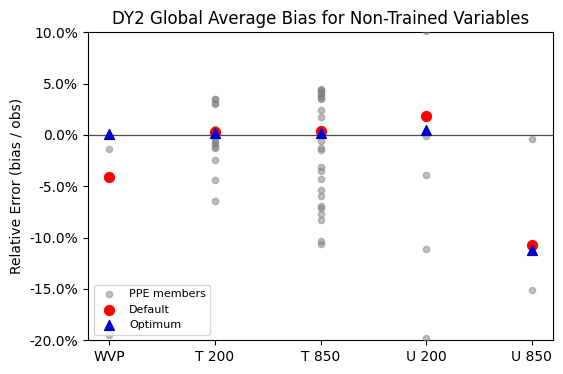

In [ ]:
variables_DY2 = [
    #{
    #    "obs":      DY2_TLWP_obs,
    #    "opt":      DY2_opt_TLWP,
    #    "default":  DY2_default_TLWP,
    #    "PPE_data": TLWP_train.iloc[-1], #DY2_default_TLWP
    #    "area":     area,
    #    "label":    "TLWP",
    #},
    {
        "obs":      DY2_WVP,
        "opt":      DY2_opt_WVP,
        "default":  DY2_default_WVP,
        "PPE_data": DY2_WVP_ppe_data.iloc[-1],
        "area":     area,
        "label":    "WVP",
    },
    {
        "obs":      DY2_temp_200,
        "opt":      DY2_opt_temp_200,
        "default":  DY2_default_temp_200,
        "PPE_data": DY2_T200_ppe_data.iloc[-1],
        "area":     area,
        "label":    "T 200",
    },
    {
        "obs":      DY2_temp_850,
        "opt":      DY2_opt_temp_850,
        "default":  DY2_default_temp_850,
        "PPE_data": DY2_T850_ppe_data.iloc[-1],
        "area":     area,
        "label":    "T 850",
    }#,
    #{
    #    "obs":      DY2_U_200,
    #    "opt":      DY2_opt_U_200,
    #    "default":  DY2_default_U_200,
    #    "PPE_data": DY2_U200_ppe_data.iloc[-1],
    #    "area":     area,
    #    "label":    "U 200",
    #},
    #{
    #    "obs":      DY2_U_850,
    #    "opt":      DY2_opt_U_850,
    #    "default":  DY2_default_U_850,
    #    "PPE_data": DY2_U850_ppe_data.iloc[-1],
    #    "area":     area,
    #    "label":    "U 850",
    #}
]

plot_multi_variable_global_comparison(variables_DY2, title="DY2 Global Average Bias for Non-Trained Variables", ylim = (-0.2, 0.1))


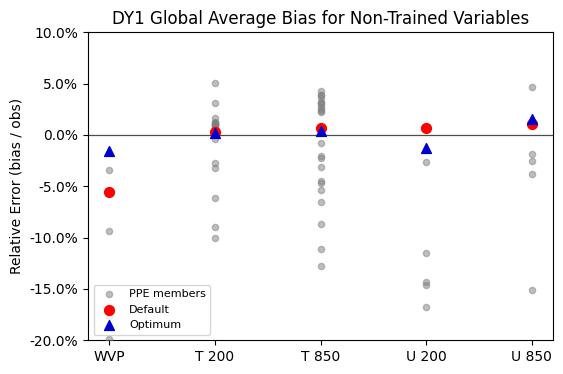

In [ ]:
variables_DY1 = [
    {
        "obs":      DY1_WVP,
        "opt":      DY1_opt_WVP,
        "default":  DY1_default_WVP,
        "PPE_data": DY1_WVP_ppe_data.iloc[-1],
        "area":     area,
        "label":    "WVP",
    },
    {
        "obs":      DY1_temp_200,
        "opt":      DY1_opt_temp_200,
        "default":  DY1_default_temp_200,
        "PPE_data": DY1_T200_ppe_data.iloc[-1],
        "area":     area,
        "label":    "T 200",
    },
    {
        "obs":      DY1_temp_850,
        "opt":      DY1_opt_temp_850,
        "default":  DY1_default_temp_850,
        "PPE_data": DY1_T850_ppe_data.iloc[-1],
        "area":     area,
        "label":    "T 850",
    }#,
    #{
    #    "obs":      DY1_U_200,
    #    "opt":      DY1_opt_U_200,
    #    "default":  DY1_default_U_200,
    #    "PPE_data": DY1_U200_ppe_data.iloc[-1],
    #    "area":     area,
    #    "label":    "U 200",
    #},
    #{
    #    "obs":      DY1_U_850,
    #    "opt":      DY1_opt_U_850,
    #    "default":  DY1_default_U_850,
    #    "PPE_data": DY1_U850_ppe_data.iloc[-1],
    #    "area":     area,
    #    "label":    "U 850",
    #}
]

plot_multi_variable_global_comparison(variables_DY1, title="DY1 Global Average Bias for Non-Trained Variables", ylim = (-0.2, 0.1))


#### Geographic plot

In [39]:
lon_adj = np.where(lon > 180, lon - 360, lon) #lon is 0-360, convert to -180 to 180

In [ ]:
def fig_geographic(obsvar, optvar, title, label):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5),
                                    subplot_kw={'projection': ccrs.PlateCarree()})
    vmin, vmax = min(obsvar.min(), optvar.min()), max(obsvar.max(), optvar.max()) # same vmin/vmax for colorbar
    
    scatter1 = ax1.scatter(lon_adj, lat, c=obsvar, vmin=vmin, vmax=vmax, transform=ccrs.PlateCarree())
    ax1.coastlines()
    ax1.set_title('Observations')
    
    scatter2 = ax2.scatter(lon_adj, lat, c=optvar, vmin=vmin, vmax=vmax, transform=ccrs.PlateCarree())
    ax2.coastlines()
    ax2.set_title('Optimum')
    
    fig.colorbar(scatter1, ax=[ax1, ax2], label=label, shrink=0.8)
    fig.suptitle(title, x=0.45, y=0.8)
    #plt.tight_layout()
    plt.show()

In [71]:
def fig_geographic_optdef(defvar, optvar, title, label, extra_data=None):
    diff = optvar - defvar

    all_diffs = [np.asarray(diff).flatten()]
    if extra_data is not None:
        for def_e, opt_e in extra_data:
            d = np.asarray(opt_e).flatten() - np.asarray(def_e).flatten()
            all_diffs.append(d)
    combined = np.concatenate(all_diffs)
    valid_combined = combined[~np.isnan(combined)]
    absmax = max(abs(np.percentile(valid_combined, 2)), abs(np.percentile(valid_combined, 98)))
    vmin, vmax = -absmax, absmax
    
    fig, ax = plt.subplots(figsize=(10, 4.5))
    m = Basemap(projection='robin', lon_0=0, resolution='l', ax=ax)

    # Transform coordinates to map projection
    mx, my = m(lon_adj, lat)

    # Create triangulation in projected space
    triang = tri.Triangulation(mx, my)

    # Mask spurious triangles (long edges from dateline wrapping)
    tri_x = mx[triang.triangles]
    tri_y = my[triang.triangles]
    edge_lengths = np.sqrt(
        np.diff(np.c_[tri_x, tri_x[:, 0:1]], axis=1)**2 +
        np.diff(np.c_[tri_y, tri_y[:, 0:1]], axis=1)**2
    )
    x_range = mx.max() - mx.min()
    mask = edge_lengths.max(axis=1) > 0.05 * x_range
    triang.set_mask(mask)

    # Plot with BrBG colormap and symmetric vmin/vmax
    tcf = plt.tricontourf(triang, diff, cmap='PRGn_r', vmin=vmin, vmax=vmax, levels = np.linspace(vmin, vmax, 51), extend='both')

    m.drawcoastlines()
   #m.drawcountries()
    ax.set_title(title + ": Optimum - Default values")
    plt.colorbar(tcf, ax=ax, label=label, shrink=0.8)
    plt.savefig(str(paths.FIGURES_DIR / 'geographic_plots') + '/'+title.replace(' ', '_') + '_optdef.png', bbox_inches='tight', dpi=150)
    plt.show()

In [53]:
def fig_geographic_optdef_T850(defvar, optvar, title, label, extra_data=None):
    defvar  = np.asarray(defvar).flatten()
    optvar  = np.asarray(optvar).flatten()
    lon_all = np.asarray(lon_adj).flatten()
    lat_all = np.asarray(lat).flatten()

    diff = optvar - defvar          # NaN wherever either input is NaN

    all_diffs = [diff[~np.isnan(diff)]]
    if extra_data is not None:
        for def_e, opt_e in extra_data:
            d = np.asarray(opt_e).flatten() - np.asarray(def_e).flatten()
            all_diffs.append(d[~np.isnan(d)])
    valid_combined = np.concatenate(all_diffs)
    absmax = max(abs(np.percentile(valid_combined, 2)), abs(np.percentile(valid_combined, 98)))
    vmin, vmax = -absmax, absmax

    fig, ax = plt.subplots(figsize=(12, 6))
    m = Basemap(projection='robin', lon_0=0, resolution='l', ax=ax)
    mx, my = m(lon_all, lat_all)

    triang = tri.Triangulation(mx, my)

    # Mask triangles that touch any NaN vertex → renders as white holes
    tri_nan_mask = np.isnan(diff)[triang.triangles].any(axis=1)

    # Also mask spuriously long triangles (dateline wrap artefacts)
    tri_x = mx[triang.triangles]
    tri_y = my[triang.triangles]
    edge_lengths = np.sqrt(
        np.diff(np.c_[tri_x, tri_x[:, 0:1]], axis=1)**2 +
        np.diff(np.c_[tri_y, tri_y[:, 0:1]], axis=1)**2
    )
    median_edge = np.median(edge_lengths)
    edge_mask = edge_lengths.max(axis=1) > 3 * median_edge

    triang.set_mask(tri_nan_mask | edge_mask)

    # Replace NaN with 0 so tricontourf doesn't complain; masked triangles won't be drawn
    diff_safe = np.where(np.isnan(diff), 0.0, diff)
    tcf = plt.tricontourf(triang, diff_safe, cmap='PRGn_r',
                          levels=np.linspace(vmin, vmax, 51), extend='both')
    m.drawcoastlines()
    ax.set_title(title + ': Optimum - Default values')
    plt.colorbar(tcf, ax=ax, label=label, shrink=0.8)
    plt.savefig(str(paths.FIGURES_DIR / 'geographic_plots') + '/'+title.replace(' ', '_') + '_optdef.png', bbox_inches='tight', dpi=150)
    plt.show()

In [145]:
def fig_geographic_optdef_WVP(defvar, optvar, title, label, extra_data=None):
    defvar = np.asarray(defvar)
    optvar = np.asarray(optvar)
    mx_all = np.asarray(lon_adj)
    lat_all = np.asarray(lat)

    diff = optvar - defvar

    all_diffs = [np.asarray(diff).flatten()]
    if extra_data is not None:
        for def_e, opt_e in extra_data:
            d = np.asarray(opt_e).flatten() - np.asarray(def_e).flatten()
            all_diffs.append(d)
    combined = np.concatenate(all_diffs)
    valid_combined = combined[~np.isnan(combined)]
    absmax = max(abs(np.percentile(valid_combined, 2)), abs(np.percentile(valid_combined, 98)))
    vmin, vmax = -absmax, absmax

    fig, ax = plt.subplots(figsize=(12, 6))
    m = Basemap(projection='robin', lon_0=0, resolution='l', ax=ax)
    mx, my = m(mx_all, lat_all)
    triang = tri.Triangulation(mx, my)
    tri_x = mx[triang.triangles]
    tri_y = my[triang.triangles]
    edge_lengths = np.sqrt(
        np.diff(np.c_[tri_x, tri_x[:, 0:1]], axis=1)**2 +
        np.diff(np.c_[tri_y, tri_y[:, 0:1]], axis=1)**2
    )
    x_range = mx.max() - mx.min()
    mask = edge_lengths.max(axis=1) > 0.05 * x_range
    triang.set_mask(mask)
    tcf = plt.tricontourf(triang, diff, cmap='PRGn_r', levels=np.linspace(vmin, vmax, 51), extend='both')
    m.drawcoastlines()
    ax.set_title(title + ": Optimum - Default values")
    plt.colorbar(tcf, ax=ax, label=label, shrink=0.75)
    plt.savefig(str(paths.FIGURES_DIR / 'geographic_plots') + '/'+title.replace(' ', '_') + '_optdef.png', bbox_inches='tight', dpi=150)
    plt.show()

In [ ]:
def fig_geographic_bias(obsvar, optvar, defvar, title, label):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5),
                                    subplot_kw={'projection': ccrs.PlateCarree()})
    def_err_var = defvar - obsvar # defining the bias for the default
    opt_err_var = optvar - obsvar # defining the bias for the optimal
    vmin, vmax = min(def_err_var.min(), opt_err_var.min()), max(def_err_var.max(), opt_err_var.max()) # same vmin/vmax for colorbar
    
    scatter1 = ax1.scatter(lon_adj, lat, c=opt_err_var, vmin=vmin, vmax=vmax, cmap='seismic', transform=ccrs.PlateCarree())
    ax1.coastlines()
    ax1.set_title('Optimum')
    
    scatter2 = ax2.scatter(lon_adj, lat, c=def_err_var, vmin=vmin, vmax=vmax, cmap='seismic', transform=ccrs.PlateCarree())
    ax2.coastlines()
    ax2.set_title('Default')
    
    fig.colorbar(scatter1, ax=[ax1, ax2], label=label, shrink=0.8)
    fig.suptitle(title, x=0.45, y=0.8)
    #plt.tight_layout()
    plt.show()

In [130]:
def fig_geographic_doublebias(obsvar, optvar, defvar, title, label, extra_data=None):
    # Create mask where observations are valid
    valid = (~np.isnan(obsvar) & ~np.isnan(optvar) & ~np.isnan(defvar)).values

    # Apply mask to all arrays
    obsvar_v = obsvar.values[valid]
    optvar_v = optvar.values[valid]
    defvar_v = defvar.values[valid]
    lon_v    = lon_adj[valid]
    lat_v    = lat[valid]

    def_err_var = abs(defvar_v - obsvar_v)
    opt_err_var = abs(optvar_v - obsvar_v)
    diff = opt_err_var - def_err_var  # plain numpy array, same size as lon_v/lat_v

    all_diffs = [diff]
    if extra_data is not None:
        for obs_e, opt_e, def_e in extra_data:
            obs_e = np.asarray(obs_e).flatten()
            opt_e = np.asarray(opt_e).flatten()
            def_e = np.asarray(def_e).flatten()
            d = abs(opt_e - obs_e) - abs(def_e - obs_e)
            all_diffs.append(d[~np.isnan(d)])
    combined = np.concatenate(all_diffs)
    absmax = max(abs(np.percentile(combined, 2)), abs(np.percentile(combined, 98)))

    fig, ax = plt.subplots(figsize=(12, 6))
    m = Basemap(projection='robin', lon_0=0, resolution='l', ax=ax)

    mx, my = m(lon_v, lat_v)  # use masked coordinates, not full lon_adj/lat

    triang = tri.Triangulation(mx, my)

    # Mask triangles with non-finite z values
    finite_mask = ~np.isfinite(diff)
    tri_finite_mask = finite_mask[triang.triangles].any(axis=1)

    # Mask spurious long triangles
    tri_x = mx[triang.triangles]
    tri_y = my[triang.triangles]
    edge_lengths = np.sqrt(
        np.diff(np.c_[tri_x, tri_x[:, 0:1]], axis=1)**2 +
        np.diff(np.c_[tri_y, tri_y[:, 0:1]], axis=1)**2
    )
    x_range = mx.max() - mx.min()
    edge_mask = edge_lengths.max(axis=1) > 0.05 * x_range

    triang.set_mask(edge_mask | tri_finite_mask)

    tcf = plt.tricontourf(triang, diff, levels=np.linspace(-absmax, absmax, 51),
                          cmap='bwr', extend='both') #seismic

    m.drawcoastlines()
    #m.drawcountries(linewidth=0.5)
    ax.set_title(title + ": Abs Opt Bias - Abs Default Bias")
    plt.colorbar(tcf, ax=ax, label=label, shrink=0.75)
    plt.savefig(str(paths.FIGURES_DIR / 'geographic_plots') + '/'+ title.replace(' ', '_') + '_doublebias.png', bbox_inches='tight', dpi=150)
    plt.show()

In [137]:
def fig_geographic_doublebias_T850(obsvar, optvar, defvar, title, label, extra_data=None):
    obsvar  = np.asarray(obsvar).flatten()
    optvar  = np.asarray(optvar).flatten()
    defvar  = np.asarray(defvar).flatten()
    lon_all = np.asarray(lon_adj).flatten()
    lat_all = np.asarray(lat).flatten()

    def_err = abs(defvar - obsvar)
    opt_err = abs(optvar - obsvar)
    diff = opt_err - def_err        # NaN wherever any input is NaN

    all_diffs = [diff[~np.isnan(diff)]]
    if extra_data is not None:
        for obs_e, opt_e, def_e in extra_data:
            obs_e = np.asarray(obs_e).flatten()
            opt_e = np.asarray(opt_e).flatten()
            def_e = np.asarray(def_e).flatten()
            d = abs(opt_e - obs_e) - abs(def_e - obs_e)
            all_diffs.append(d[~np.isnan(d)])
    valid_combined = np.concatenate(all_diffs)
    absmax = max(abs(np.percentile(valid_combined, 2)), abs(np.percentile(valid_combined, 98)))

    fig, ax = plt.subplots(figsize=(12, 6))
    m = Basemap(projection='robin', lon_0=0, resolution='l', ax=ax)
    mx, my = m(lon_all, lat_all)

    triang = tri.Triangulation(mx, my)

    # Mask triangles that touch any NaN vertex → renders as white holes
    tri_nan_mask = np.isnan(diff)[triang.triangles].any(axis=1)

    # Also mask spuriously long triangles (dateline wrap artefacts)
    tri_x = mx[triang.triangles]
    tri_y = my[triang.triangles]
    edge_lengths = np.sqrt(
        np.diff(np.c_[tri_x, tri_x[:, 0:1]], axis=1)**2 +
        np.diff(np.c_[tri_y, tri_y[:, 0:1]], axis=1)**2
    )
    median_edge = np.median(edge_lengths)
    edge_mask = edge_lengths.max(axis=1) > 3 * median_edge

    triang.set_mask(tri_nan_mask | edge_mask)

    diff_safe = np.where(np.isnan(diff), 0.0, diff)
    tcf = plt.tricontourf(triang, diff_safe,
                          levels=np.linspace(-absmax, absmax, 51),
                          cmap='bwr', extend='both')
    m.drawcoastlines()
    ax.set_title(title + ': Abs Opt Bias - Abs Default Bias')
    plt.colorbar(tcf, ax=ax, label=label, shrink=0.75)
    plt.savefig(str(paths.FIGURES_DIR / 'geographic_plots') + '/'+ title.replace(' ', '_') + '_doublebias.png', bbox_inches='tight', dpi=150)
    plt.show()


In [140]:
def fig_geographic_doublebias_WVP(obsvar, optvar, defvar, title, label, extra_data=None):
    # Force everything to numpy upfront
    obsvar = np.asarray(obsvar)
    optvar = np.asarray(optvar)
    defvar = np.asarray(defvar)
    lon_v_all = np.asarray(lon_adj)
    lat_v_all = np.asarray(lat)

    valid = ~np.isnan(obsvar) & ~np.isnan(optvar) & ~np.isnan(defvar)

    obsvar_v = obsvar[valid]
    optvar_v = optvar[valid]
    defvar_v = defvar[valid]
    lon_v    = lon_v_all[valid]
    lat_v    = lat_v_all[valid]

    def_err_var = abs(defvar_v - obsvar_v)
    opt_err_var = abs(optvar_v - obsvar_v)
    diff = opt_err_var - def_err_var

    all_diffs = [diff]
    if extra_data is not None:
        for obs_e, opt_e, def_e in extra_data:
            obs_e = np.asarray(obs_e).flatten()
            opt_e = np.asarray(opt_e).flatten()
            def_e = np.asarray(def_e).flatten()
            d = abs(opt_e - obs_e) - abs(def_e - obs_e)
            all_diffs.append(d[~np.isnan(d)])
    combined = np.concatenate(all_diffs)
    absmax = max(abs(np.percentile(combined, 2)), abs(np.percentile(combined, 98)))

    fig, ax = plt.subplots(figsize=(12, 6))
    m = Basemap(projection='robin', lon_0=0, resolution='l', ax=ax)
    mx, my = m(lon_v, lat_v)
    triang = tri.Triangulation(mx, my)
    finite_mask = ~np.isfinite(diff)
    tri_finite_mask = finite_mask[triang.triangles].any(axis=1)
    tri_x = mx[triang.triangles]
    tri_y = my[triang.triangles]
    edge_lengths = np.sqrt(
        np.diff(np.c_[tri_x, tri_x[:, 0:1]], axis=1)**2 +
        np.diff(np.c_[tri_y, tri_y[:, 0:1]], axis=1)**2
    )
    x_range = mx.max() - mx.min()
    edge_mask = edge_lengths.max(axis=1) > 0.05 * x_range
    triang.set_mask(edge_mask | tri_finite_mask)
    tcf = plt.tricontourf(triang, diff, levels=np.linspace(-absmax, absmax, 21),
                          cmap='bwr', extend='both')
    m.drawcoastlines()
    #m.drawcountries(linewidth=0.5)
    ax.set_title(title + ": Abs Opt Bias - Abs Default Bias")
    plt.colorbar(tcf, ax=ax, label=label, shrink=0.8)
    plt.savefig(str(paths.FIGURES_DIR / 'geographic_plots') + '/'+ title.replace(' ', '_') + '_doublebias.png', bbox_inches='tight', dpi=150)
    plt.show()

In [60]:
def fig_geographic_def(defvar, title, label, extra_data=None):
    all_data = [np.asarray(defvar).flatten()]
    combined = np.concatenate(all_data)
    valid_combined = combined[~np.isnan(combined)]
    vmin, vmax = np.percentile(valid_combined, 0), np.percentile(valid_combined, 98)

    fig, ax = plt.subplots(figsize=(12, 6))
    m = Basemap(projection='robin', lon_0=0, resolution='l', ax=ax)
    mx, my = m(lon_adj, lat)
    triang = tri.Triangulation(mx, my)
    tri_x = mx[triang.triangles]
    tri_y = my[triang.triangles]
    edge_lengths = np.sqrt(
        np.diff(np.c_[tri_x, tri_x[:, 0:1]], axis=1)**2 +
        np.diff(np.c_[tri_y, tri_y[:, 0:1]], axis=1)**2
    )
    x_range = mx.max() - mx.min()
    mask = edge_lengths.max(axis=1) > 0.05 * x_range
    triang.set_mask(mask)
    tcf = plt.tricontourf(triang, defvar, cmap='jet', vmin=vmin, vmax=vmax, levels=np.linspace(vmin, vmax, 101), extend='max')
    m.drawcoastlines()
    ax.set_title(title)
    plt.colorbar(tcf, ax=ax, label=label, shrink=0.8)
    plt.savefig(str(paths.FIGURES_DIR / 'geographic_plots') + '/' + title.replace(' ', '_') + '_def.png', bbox_inches='tight', dpi=150)
    plt.show()

### Combined a,b,c figures
Each figure below reuses the existing optdef / doublebias / rmse plotting functions unchanged and composites their output into one panel with (a.), (b.), (c.) labels.

In [ ]:
import io
from PIL import Image

def render_to_array(plot_func, *args, panel_scale=0.6, **kwargs):
    """Run an existing plotting function headlessly and return its figure as a pixel array.

    panel_scale shrinks the original figure's canvas (in inches) before rasterizing it.
    Font sizes are set in points (absolute), so shrinking the canvas alone makes the
    same text occupy a larger fraction of the panel -- no fontsize needs to change.
    """
    show_orig = plt.show
    plt.show = lambda *a, **k: None
    try:
        plot_func(*args, **kwargs)
        fig = plt.gcf()
        w, h = fig.get_size_inches()
        fig.set_size_inches(w * panel_scale, h * panel_scale)
        buf = io.BytesIO()
        fig.savefig(buf, format='png', dpi=300, bbox_inches='tight')
        plt.close(fig)
    finally:
        plt.show = show_orig
    buf.seek(0)
    return np.array(Image.open(buf))


COMBINED_FIGURES_DIR = str(paths.FIGURES_DIR / 'tri_figs')


def make_abc_figure(suptitle, panel_calls, figsize=(10, 8), panel_scale=0.6, savepath=None):
    """panel_calls: list of 3 (func, args, kwargs) tuples, in a/b/c order.

    panel_scale can be a single float (applied to all three panels) or a list/tuple
    of 3 floats to scale each panel (a, b, c) independently -- handy since the line
    plot (c) often needs a bigger scale than the maps (a, b) to avoid clipped text.
    """
    if isinstance(panel_scale, (list, tuple)):
        scales = panel_scale
    else:
        scales = [panel_scale] * 3
    images = [render_to_array(func, *args, panel_scale=scale, **kwargs)
              for (func, args, kwargs), scale in zip(panel_calls, scales)]

    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])
    axes = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])]

    with plt.rc_context({'mathtext.fontset': 'cm'}):
        for ax, img, letter in zip(axes, images, ['a', 'b', 'c']):
            ax.imshow(img)
            ax.axis('off')
            ax.text(0.0, 1.0, rf'$\mathrm{{({letter}.)}}$', transform=ax.transAxes,
                    fontsize=14, va='bottom', ha='left')

    #if suptitle:
        #fig.suptitle(suptitle, fontsize=15, y=0.92)
    plt.tight_layout()

    if savepath is None and suptitle:
        os.makedirs(COMBINED_FIGURES_DIR, exist_ok=True)
        savepath = os.path.join(COMBINED_FIGURES_DIR, suptitle.replace(' ', '_') + '.png')
    if savepath:
        fig.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()


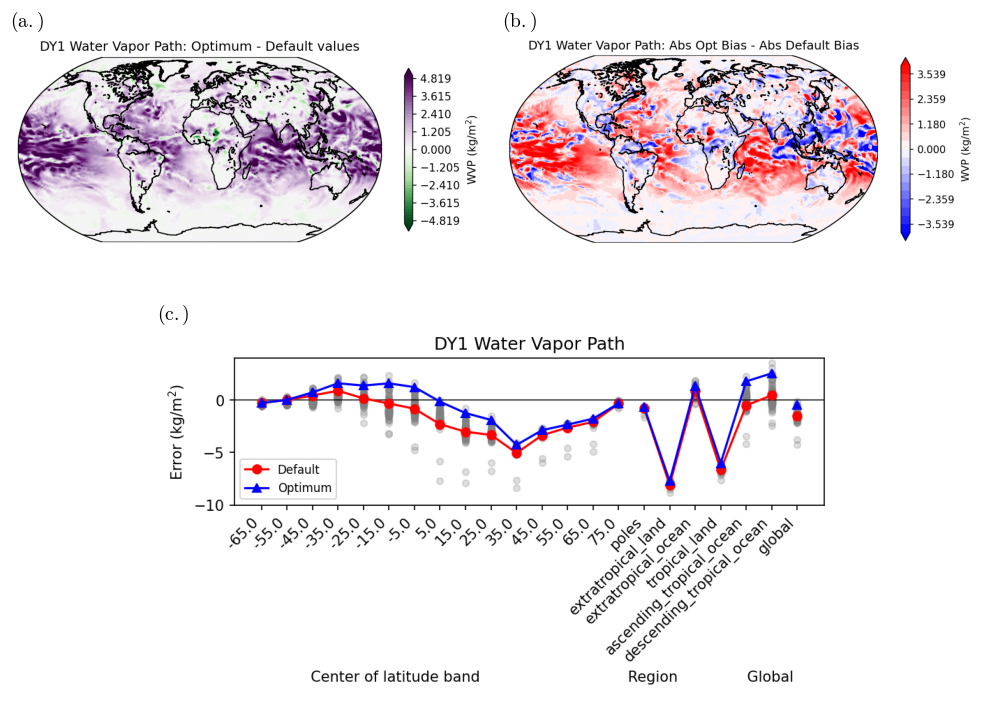

In [ ]:
make_abc_figure(
    "DY1 Water Vapor Path",
    [
        (fig_geographic_optdef, (DY1_default_WVP, DY1_opt_WVP, 'DY1 Water Vapor Path', 'WVP (kg/m$^2$)'), dict(extra_data=[(DY2_default_WVP, DY2_opt_WVP)])),
        (fig_geographic_doublebias_WVP, (DY1_WVP, DY1_opt_WVP, DY1_default_WVP, 'DY1 Water Vapor Path', 'WVP (kg/m$^2$)'), dict(extra_data=[(DY2_WVP, DY2_opt_WVP, DY2_default_WVP)])),
        (plot_rmse_good, (DY1_default_WVP, DY1_opt_WVP, DY1_WVP, DY1_WVP_ppe_data, area, lat, lon), dict(title='DY1 Water Vapor Path', units='kg/m$^2$', z_num=18, r_num=6,
        ylim=(-10, 4),
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


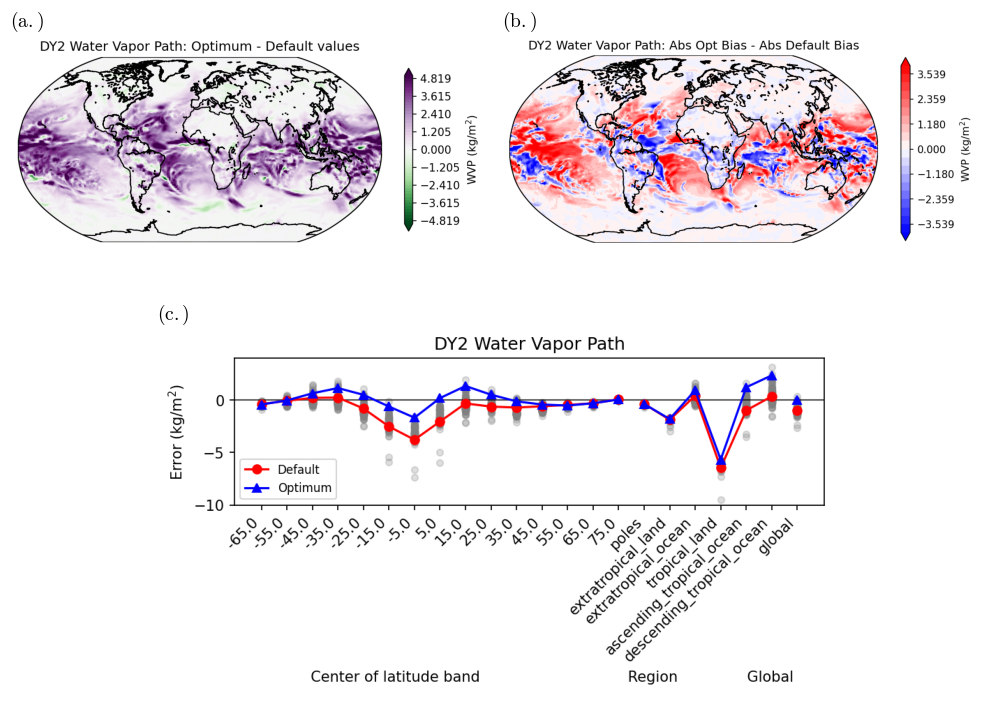

In [ ]:
make_abc_figure(
    "DY2 Water Vapor Path",
    [
        (fig_geographic_optdef, (DY2_default_WVP, DY2_opt_WVP, 'DY2 Water Vapor Path', 'WVP (kg/m$^2$)'), dict(extra_data=[(DY1_default_WVP, DY1_opt_WVP)])),
        (fig_geographic_doublebias_WVP, (DY2_WVP, DY2_opt_WVP, DY2_default_WVP, 'DY2 Water Vapor Path', 'WVP (kg/m$^2$)'), dict(extra_data=[(DY1_WVP, DY1_opt_WVP, DY1_default_WVP)])),
        (plot_rmse_good, (DY2_default_WVP, DY2_opt_WVP, DY2_WVP, DY2_WVP_ppe_data, area, lat, lon), dict(title='DY2 Water Vapor Path', units='kg/m$^2$', z_num=18, r_num=6,
        ylim=(-10, 4),
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


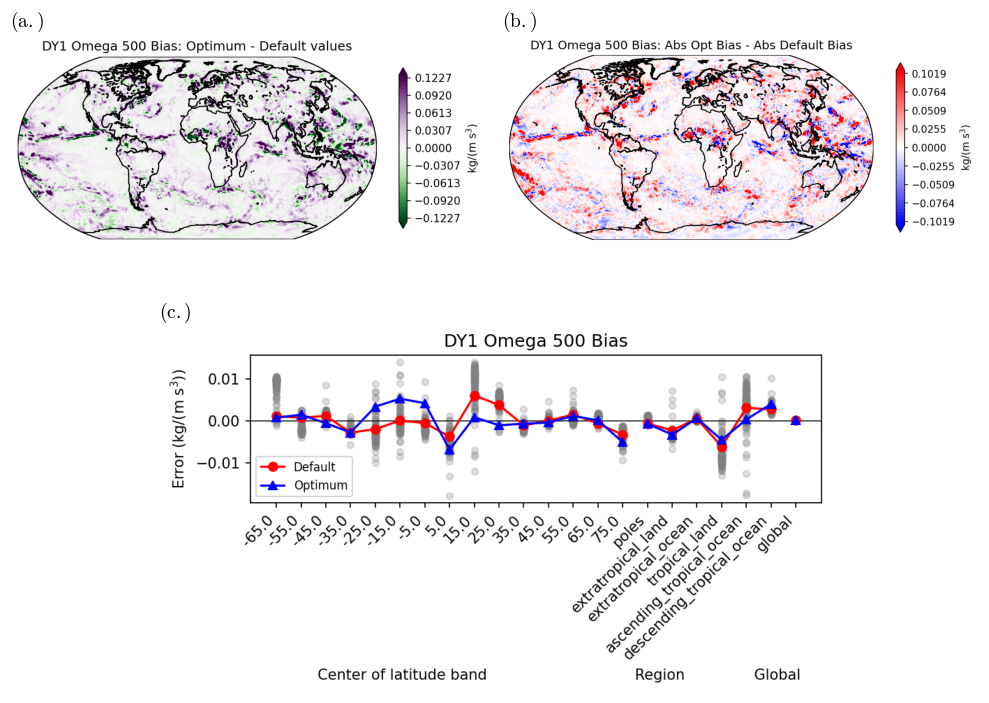

In [ ]:
make_abc_figure(
    "DY1 Omega 500",
    [
        (fig_geographic_optdef, (DY1_default_omega_500, DY1_opt_omega_500, 'DY1 Omega 500 Bias', 'kg/(m s$^3$)'), dict(extra_data=[(DY2_default_omega_500, DY2_opt_omega_500)])),
        (fig_geographic_doublebias, (DY1_omega_500, DY1_opt_omega_500, DY1_default_omega_500, 'DY1 Omega 500 Bias', 'kg/(m s$^3$)'), dict(extra_data=[(DY2_omega_500, DY2_opt_omega_500, DY2_default_omega_500)])),
        (plot_rmse_good, (DY1_default_omega_500, DY1_opt_omega_500, DY1_omega_500, DY1_Omega500_ppe_data, area, lat, lon), dict(title='DY1 Omega 500 Bias', units='kg/(m s$^3$)', z_num=18, r_num=6,
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


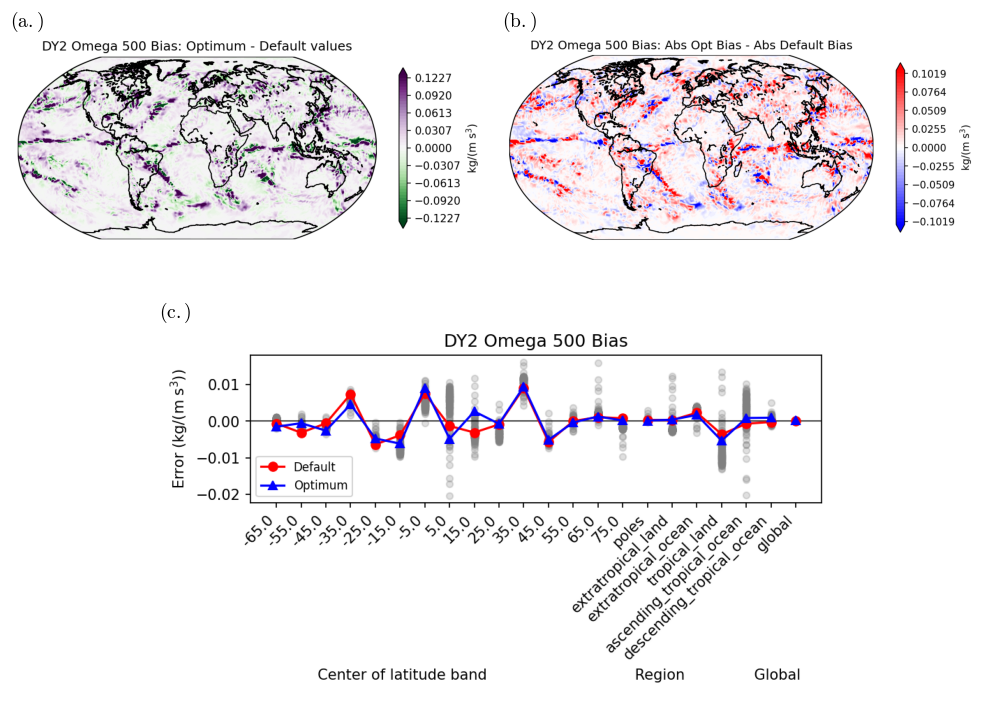

In [ ]:
make_abc_figure(
    "DY2 Omega 500",
    [
        (fig_geographic_optdef, (DY2_default_omega_500, DY2_opt_omega_500, 'DY2 Omega 500 Bias', 'kg/(m s$^3$)'), dict(extra_data=[(DY1_default_omega_500, DY1_opt_omega_500)])),
        (fig_geographic_doublebias, (DY2_omega_500, DY2_opt_omega_500, DY2_default_omega_500, 'DY2 Omega 500 Bias', 'kg/(m s$^3$)'), dict(extra_data=[(DY1_omega_500, DY1_opt_omega_500, DY1_default_omega_500)])),
        (plot_rmse_good, (DY2_default_omega_500, DY2_opt_omega_500, DY2_omega_500, DY2_Omega500_ppe_data, area, lat, lon), dict(title='DY2 Omega 500 Bias', units='kg/(m s$^3$)', z_num=18, r_num=6,
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


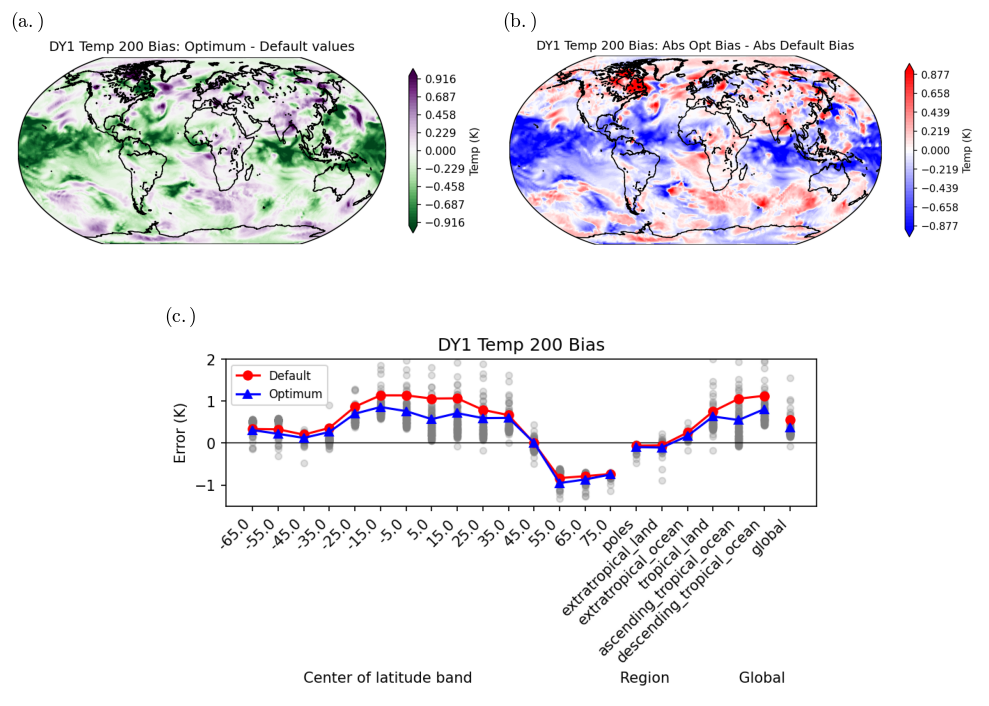

In [ ]:
make_abc_figure(
    "DY1 Temp 200",
    [
        (fig_geographic_optdef, (DY1_default_temp_200, DY1_opt_temp_200, 'DY1 Temp 200 Bias', 'Temp (K)'), dict(extra_data=[(DY2_default_temp_200, DY2_opt_temp_200)])),
        (fig_geographic_doublebias, (DY1_temp_200, DY1_opt_temp_200, DY1_default_temp_200, 'DY1 Temp 200 Bias', 'Temp (K)'), dict(extra_data=[(DY2_temp_200, DY2_opt_temp_200, DY2_default_temp_200)])),
        (plot_rmse_good, (DY1_default_temp_200, DY1_opt_temp_200, DY1_temp_200, DY1_T200_ppe_data, area, lat, lon), dict(title='DY1 Temp 200 Bias', units='K', z_num=18, r_num=6,
        ylim=(-1.5, 2),
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


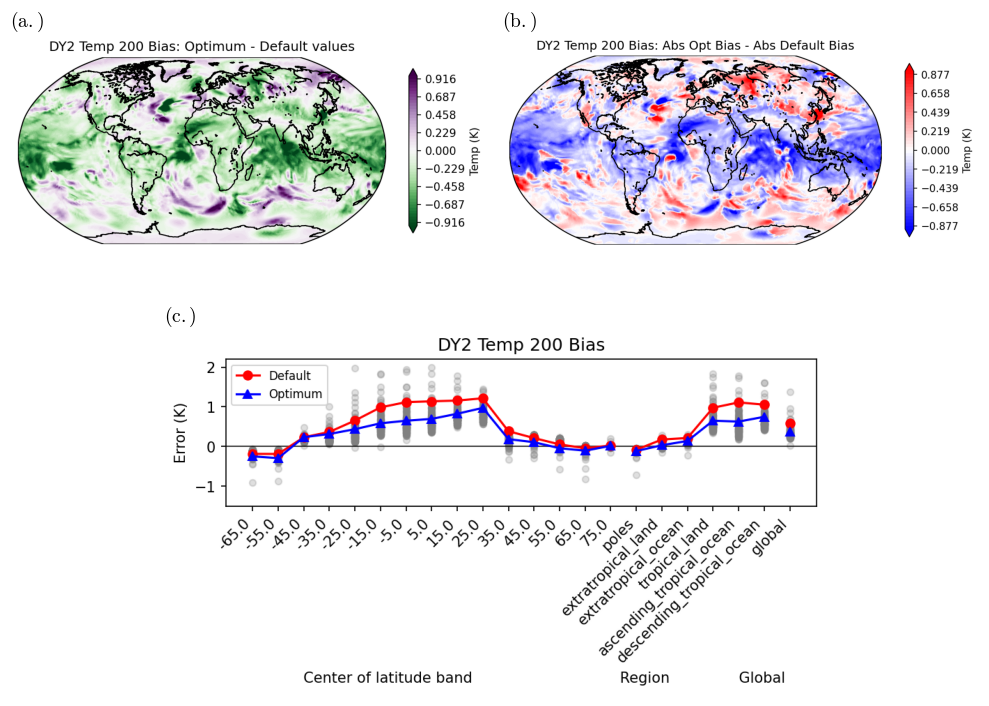

In [ ]:
make_abc_figure(
    "DY2 Temp 200 Bias",
    [
        (fig_geographic_optdef, (DY2_default_temp_200, DY2_opt_temp_200, 'DY2 Temp 200 Bias', 'Temp (K)'), dict(extra_data=[(DY1_default_temp_200, DY1_opt_temp_200)])),
        (fig_geographic_doublebias, (DY2_temp_200, DY2_opt_temp_200, DY2_default_temp_200, 'DY2 Temp 200 Bias', 'Temp (K)'), dict(extra_data=[(DY1_temp_200, DY1_opt_temp_200, DY1_default_temp_200)])),
        (plot_rmse_good, (DY2_default_temp_200, DY2_opt_temp_200, DY2_temp_200, DY2_T200_ppe_data, area, lat, lon), dict(title='DY2 Temp 200 Bias', units='K', z_num=18, r_num=6,
        ylim=(-1.5, 2.2),
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


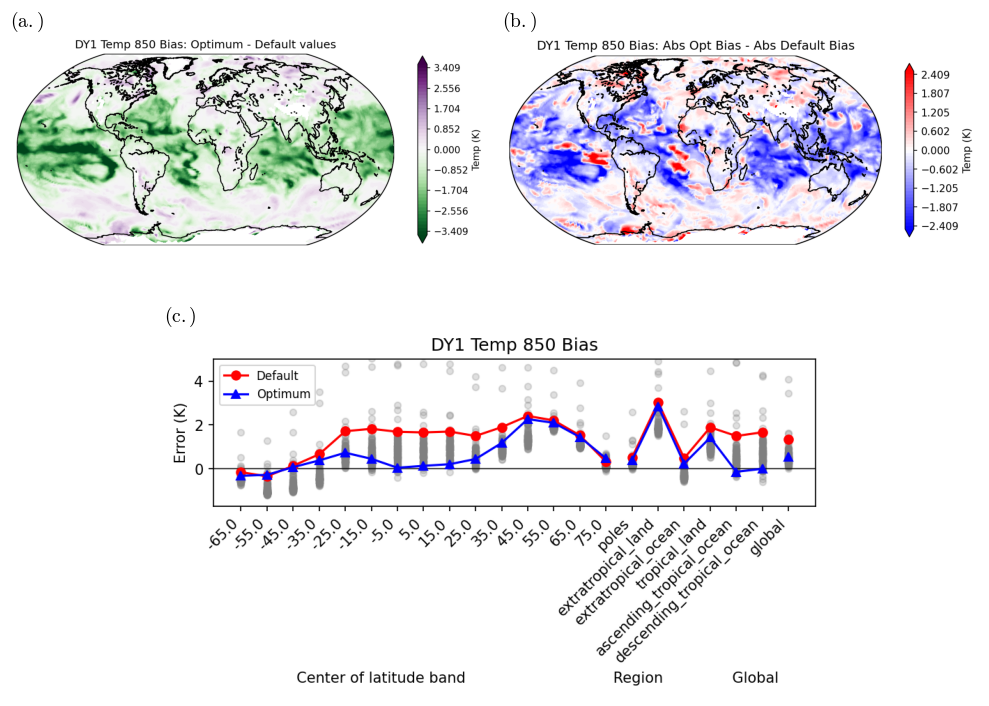

In [ ]:
make_abc_figure(
    "DY1 Temp 850 Bias",
    [
        (fig_geographic_optdef_T850, (DY1_default_temp_850_filt, DY1_opt_temp_850_filt, 'DY1 Temp 850 Bias', 'Temp (K)'), dict(extra_data=[(DY2_default_temp_850_filt, DY2_opt_temp_850_filt)])),
        (fig_geographic_doublebias_T850, (DY1_temp_850_filt, DY1_opt_temp_850_filt, DY1_default_temp_850_filt, 'DY1 Temp 850 Bias', 'Temp (K)'), dict(extra_data=[(DY2_temp_850_filt, DY2_opt_temp_850_filt, DY2_default_temp_850_filt)])),
        (plot_rmse_good, (DY1_default_temp_850_filt, DY1_opt_temp_850_filt, DY1_temp_850_filt, DY1_T850_ppe_data, area, lat, lon), dict(title='DY1 Temp 850 Bias', units='K', z_num=18, r_num=6,
        ylim=(-1.7, 5),
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


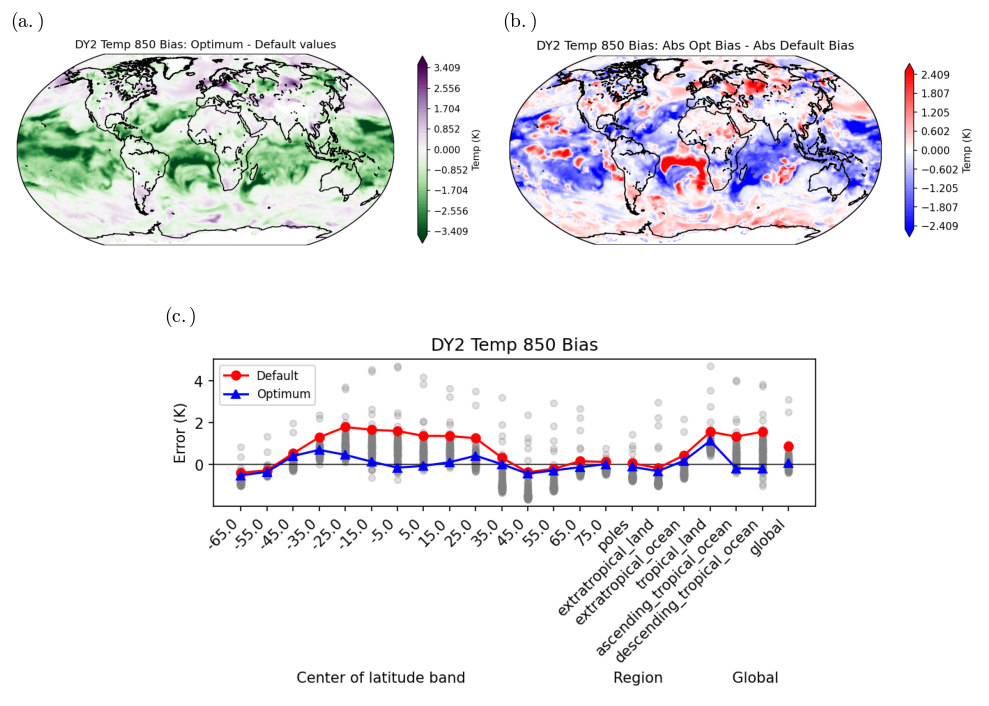

In [ ]:
make_abc_figure(
    "DY2 Temp 850 Bias",
    [
        (fig_geographic_optdef_T850, (DY2_default_temp_850_filt, DY2_opt_temp_850_filt, 'DY2 Temp 850 Bias', 'Temp (K)'), dict(extra_data=[(DY1_default_temp_850_filt, DY1_opt_temp_850_filt)])),
        (fig_geographic_doublebias_T850, (DY2_temp_850_filt, DY2_opt_temp_850_filt, DY2_default_temp_850_filt, 'DY2 Temp 850 Bias', 'Temp (K)'), dict(extra_data=[(DY1_temp_850_filt, DY1_opt_temp_850_filt, DY1_default_temp_850_filt)])),
        (plot_rmse_good, (DY2_default_temp_850_filt, DY2_opt_temp_850_filt, DY2_temp_850_filt, DY2_T850_ppe_data, area, lat, lon), dict(title='DY2 Temp 850 Bias', units='K', z_num=18, r_num=6,
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


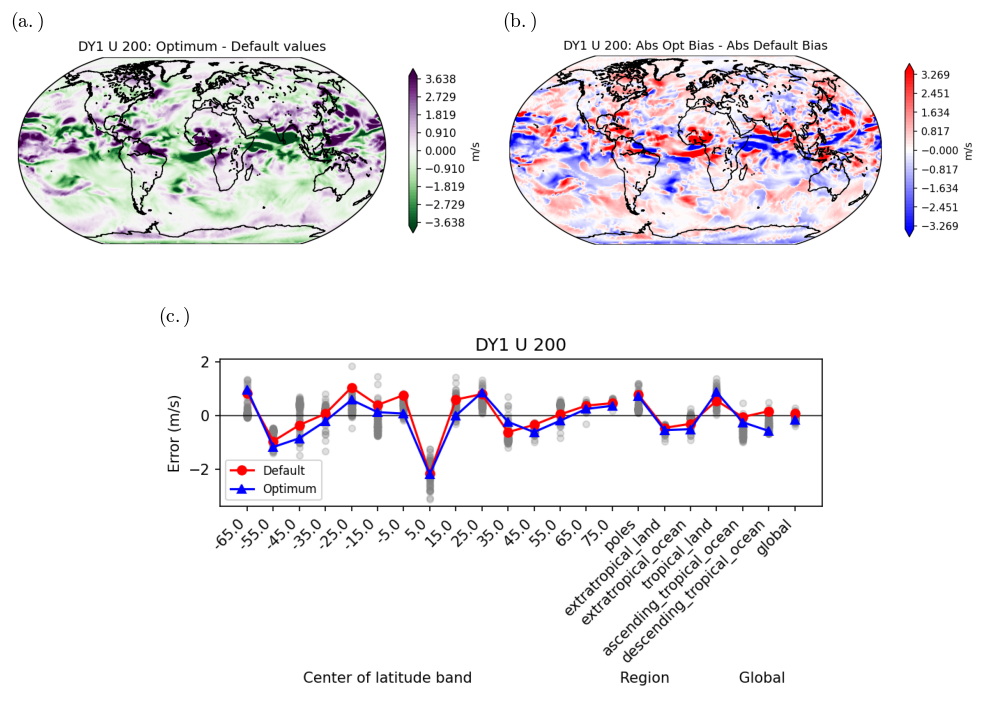

In [ ]:
make_abc_figure(
    "DY1 U 200",
    [
        (fig_geographic_optdef, (DY1_default_U_200, DY1_opt_U_200, 'DY1 U 200', 'm/s'), dict(extra_data=[(DY2_default_U_200, DY2_opt_U_200)])),
        (fig_geographic_doublebias, (DY1_U_200, DY1_opt_U_200, DY1_default_U_200, 'DY1 U 200', 'm/s'), dict(extra_data=[(DY2_U_200, DY2_opt_U_200, DY2_default_U_200)])),
        (plot_rmse_good, (DY1_default_U_200, DY1_opt_U_200, DY1_U_200, DY1_U200_ppe_data, area, lat, lon), dict(title='DY1 U 200', units='m/s', z_num=18, r_num=6,
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


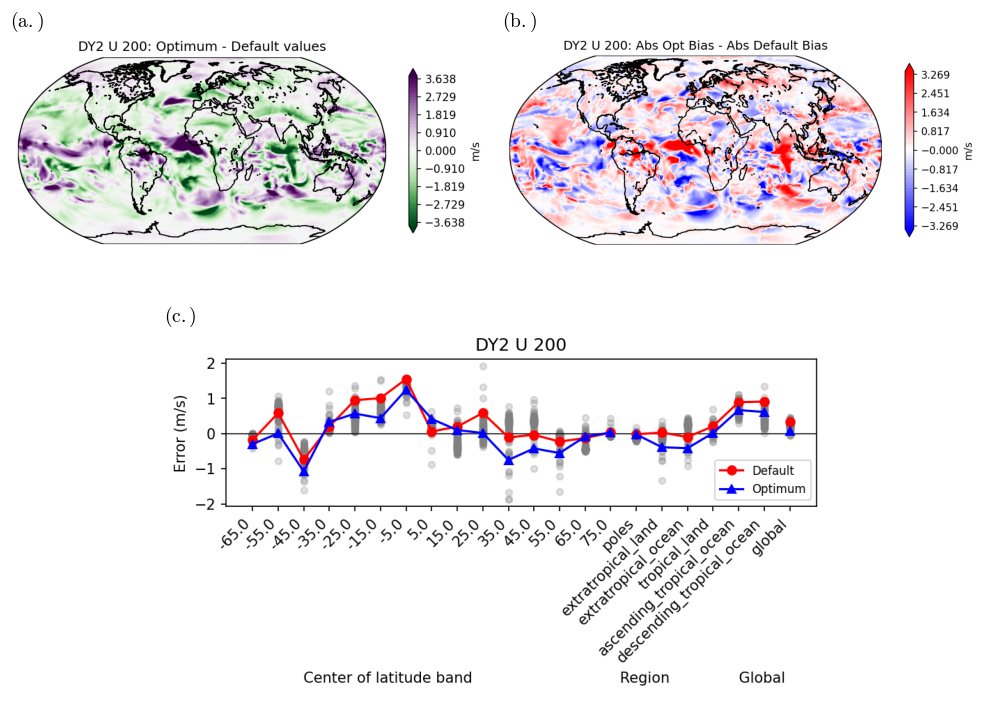

In [ ]:
make_abc_figure(
    "DY2 U 200",
    [
        (fig_geographic_optdef, (DY2_default_U_200, DY2_opt_U_200, 'DY2 U 200', 'm/s'), dict(extra_data=[(DY1_default_U_200, DY1_opt_U_200)])),
        (fig_geographic_doublebias, (DY2_U_200, DY2_opt_U_200, DY2_default_U_200, 'DY2 U 200', 'm/s'), dict(extra_data=[(DY1_U_200, DY1_opt_U_200, DY1_default_U_200)])),
        (plot_rmse_good, (DY2_default_U_200, DY2_opt_U_200, DY2_U_200, DY2_U200_ppe_data, area, lat, lon), dict(title='DY2 U 200', units='m/s', z_num=18, r_num=6,
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


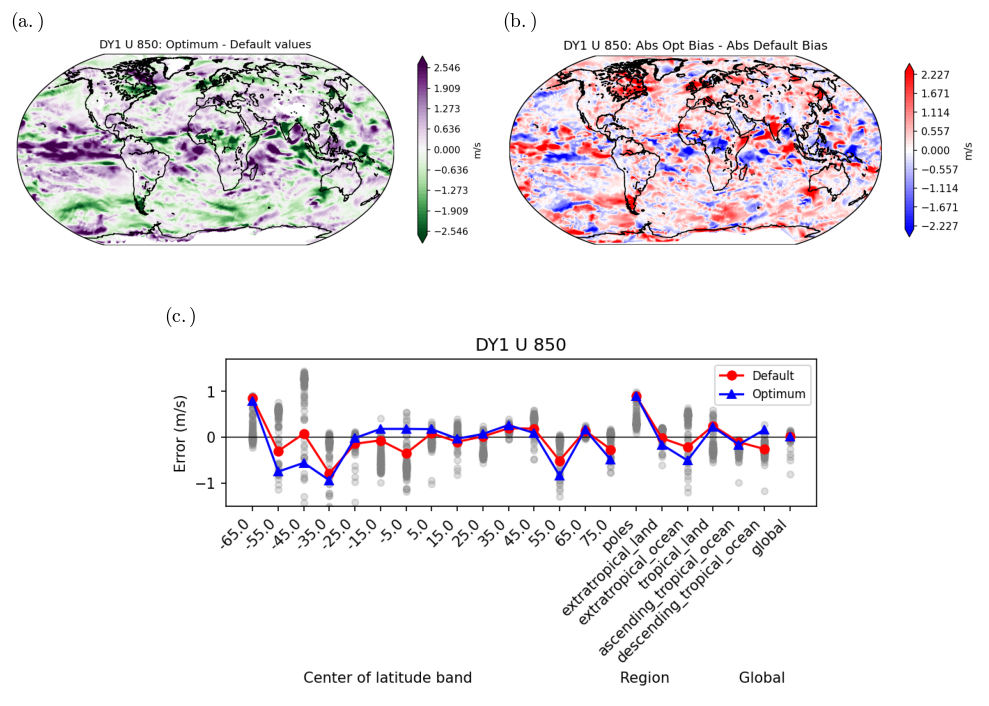

In [ ]:
make_abc_figure(
    "DY1 U 850",
    [
        (fig_geographic_optdef_T850, (DY1_default_U_850, DY1_opt_U_850, 'DY1 U 850', 'm/s'), dict(extra_data=[(DY2_default_U_850, DY2_opt_U_850)])),
        (fig_geographic_doublebias, (DY1_U_850_filt, DY1_opt_U_850, DY1_default_U_850, 'DY1 U 850', 'm/s'), dict(extra_data=[(DY2_U_850_filt, DY2_opt_U_850, DY2_default_U_850)])),
        (plot_rmse_good, (DY1_default_U_850, DY1_opt_U_850, DY1_U_850, DY1_U850_ppe_data, area, lat, lon), dict(title='DY1 U 850', units='m/s', z_num=18, r_num=6,
        ylim=(-1.5, 1.7),
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


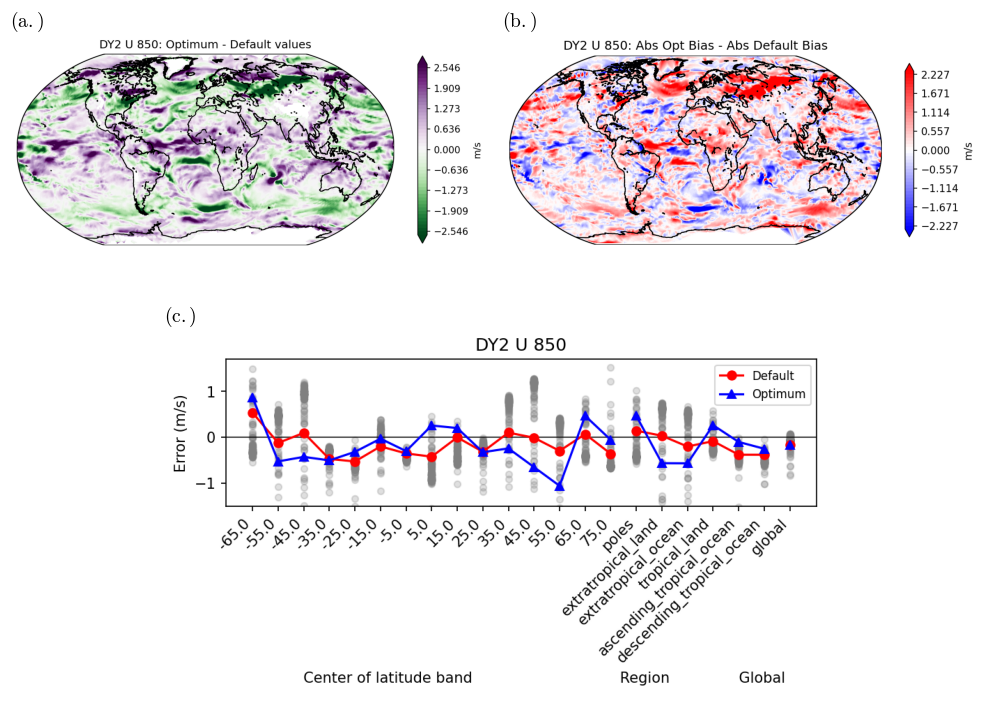

In [ ]:
make_abc_figure(
    "DY2 U 850",
    [
        (fig_geographic_optdef_T850, (DY2_default_U_850, DY2_opt_U_850, 'DY2 U 850', 'm/s'), dict(extra_data=[(DY1_default_U_850, DY1_opt_U_850)])),
        (fig_geographic_doublebias, (DY2_U_850_filt, DY2_opt_U_850, DY2_default_U_850, 'DY2 U 850', 'm/s'), dict(extra_data=[(DY1_U_850_filt, DY1_opt_U_850, DY1_default_U_850)])),
        (plot_rmse_good, (DY2_default_U_850, DY2_opt_U_850, DY2_U_850, DY2_U850_ppe_data, area, lat, lon), dict(title='DY2 U 850', units='m/s', z_num=18, r_num=6,
        ylim=(-1.5, 1.7),
    )),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


In [ ]:
make_abc_figure(
    "DY1 Precipitation",
    [
        (fig_geographic_optdef, (DY1_default_PCP*86400000, DY1_opt_PCP*86400000, 'DY1 Precipitation', 'PCP (mm/day)'),
         dict(extra_data=[(DY2_default_PCP*86400000, DY2_opt_PCP*86400000)])),
        (fig_geographic_doublebias, (DY1_PCP_obs*86400000, DY1_opt_PCP*86400000, DY1_default_PCP*86400000, 'DY1 Precipitation', 'PCP (mm/day)'),
         dict(extra_data=[(DY2_PCP_obs*86400000, DY2_opt_PCP*86400000, DY2_default_PCP*86400000)])),
        (plot_rmse_good, (DY1_default_PCP*86400000, DY1_opt_PCP*86400000, DY1_PCP_obs*86400000, PCP_train.iloc[:, 0:22]*86400000, area, lat, lon),
         dict(title="PCP", units="mm day^-1", z_num=18, r_num=6, ylim=(-1.5,1.7),
              obs_mask_default=DY1_PCP_obs, obs_mask_opt=DY1_PCP_obs)),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


NameError: name 'PCP_train' is not defined

In [ ]:
make_abc_figure(
    "DY2 Outgoing Shortwave Radiation",
    [
        (fig_geographic_optdef, (DY2_default_OSR, DY2_opt_OSR, 'DY2 Outgoing Shortwave Radiation', 'OSR (W/m$^2$)'),
         dict(extra_data=[(DY1_default_OSR, DY1_opt_OSR)])),
        (fig_geographic_doublebias, (DY2_OSR_obs, DY2_opt_OSR, DY2_default_OSR, 'DY2 Outgoing Shortwave Radiation', 'OSR (W/m$^2$)'),
         dict(extra_data=[(DY1_OSR_obs, DY1_opt_OSR, DY1_default_OSR)])),
        (plot_rmse_train, (DY2_default_OSR, DY2_opt_OSR, DY2_OSR_obs, OSR_train.iloc[:, 22:44].values, area, lat, lon, "OSR", "W m^-2"),
         dict(ylim=(-50, 85), obs_mask_default=DY2_OSR_obs, obs_mask_opt=DY2_OSR_obs)),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


In [ ]:
make_abc_figure(
    "DY2 Outgoing Longwave Radiation",
    [
        (fig_geographic_optdef, (DY2_default_OLR, DY2_opt_OLR, 'DY2 Outgoing Longwave Radiation', 'OLR (W/m$^2$)'),
         dict(extra_data=[(DY1_default_OLR, DY1_opt_OLR)])),
        (fig_geographic_doublebias, (DY2_OLR_obs, DY2_opt_OLR, DY2_default_OLR, 'DY2 Outgoing Longwave Radiation', 'OLR (W/m$^2$)'),
         dict(extra_data=[(DY1_OLR_obs, DY1_opt_OLR, DY1_default_OLR)])),
        (plot_rmse_train, (DY2_default_OLR, DY2_opt_OLR, DY2_OLR_obs, OLR_train.iloc[:, 22:44].values, area, lat, lon, "OLR", "W m^-2"),
         dict(ylim=(-20, 20), obs_mask_default=DY2_OLR_obs, obs_mask_opt=DY2_OLR_obs)),
    ],
    panel_scale=(0.75, 0.68, 0.8),
)


In [ ]:
make_abc_figure(
    "DY2 Total Liquid Water Path",
    [
        (fig_geographic_optdef, (DY2_default_TLWP, DY2_opt_TLWP, 'DY2 Total Liquid Water Path', 'TLWP (kg/m$^2$)'),
         dict(extra_data=[(DY1_default_WVP, DY1_opt_TLWP)])),
        (fig_geographic_doublebias_T850, (DY2_TLWP_obs, DY2_opt_TLWP, DY2_default_TLWP, 'DY2 Total Liquid Water Path', 'TLWP (kg/m$^2$)'),
         dict(extra_data=[(DY1_TLWP_obs, DY1_opt_TLWP, DY1_default_TLWP)])),
        (plot_rmse_train, (DY2_default_TLWP, DY2_opt_TLWP, DY2_TLWP_obs, TLWP_train.iloc[:, 22:44].values, area, lat, lon, "TLWP", "kg m^-2"),
         dict(obs_mask_default=DY2_TLWP_obs, obs_mask_opt=DY2_TLWP_obs)),
    ],
    panel_scale=(0.75, 0.68, 0.9),
)


NameError: name 'plot_rmse_train' is not defined